# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [52]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

In [53]:
#!rm SUSY.csv

In [54]:
#!gunzip SUSY.csv.gz

In [55]:
ls -lh

total 5178280
-rw-r--r--@ 1 doodles  staff   357K Oct 23 22:21 Lab.7.ipynb
-rw-r--r--@ 1 doodles  staff   149K Oct 23 22:21 Lab.7.pdf
-rw-r--r--@ 1 doodles  staff   4.4M Oct 24 22:17 Lab.7.solution.ipynb
-rw-r--r--  1 doodles  staff   228M Oct 23 23:36 SUSY-small.csv
-rw-r--r--  1 doodles  staff   2.2G Oct 23 23:23 SUSY.csv


The data is provided as a comma separated file.

In [56]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [57]:
!ls -lh

total 5178280
-rw-r--r--@ 1 doodles  staff   357K Oct 23 22:21 Lab.7.ipynb
-rw-r--r--@ 1 doodles  staff   149K Oct 23 22:21 Lab.7.pdf
-rw-r--r--@ 1 doodles  staff   4.4M Oct 24 22:17 Lab.7.solution.ipynb
-rw-r--r--  1 doodles  staff   228M Oct 23 23:36 SUSY-small.csv
-rw-r--r--  1 doodles  staff   2.2G Oct 23 23:23 SUSY.csv


We see that we have 5 million datapoints.

In [58]:
!wc -l SUSY.csv

 5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [59]:
!head -500000 SUSY.csv > SUSY-small.csv

In [60]:
ls -lh

total 5178280
-rw-r--r--@ 1 doodles  staff   357K Oct 23 22:21 Lab.7.ipynb
-rw-r--r--@ 1 doodles  staff   149K Oct 23 22:21 Lab.7.pdf
-rw-r--r--@ 1 doodles  staff   4.4M Oct 24 22:17 Lab.7.solution.ipynb
-rw-r--r--@ 1 doodles  staff   228M Oct 24 22:21 SUSY-small.csv
-rw-r--r--  1 doodles  staff   2.2G Oct 23 23:23 SUSY.csv


In [61]:
! wc -l SUSY-small.csv

  500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [62]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [63]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [64]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [65]:
FeatureNames

['M_TR_2',
 'axial_MET',
 'MT2',
 'cos_theta_r1',
 'S_R',
 'dPhi_r_b',
 'M_R',
 'MET_rel',
 'M_Delta_R',
 'R']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [66]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [67]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [68]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [69]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


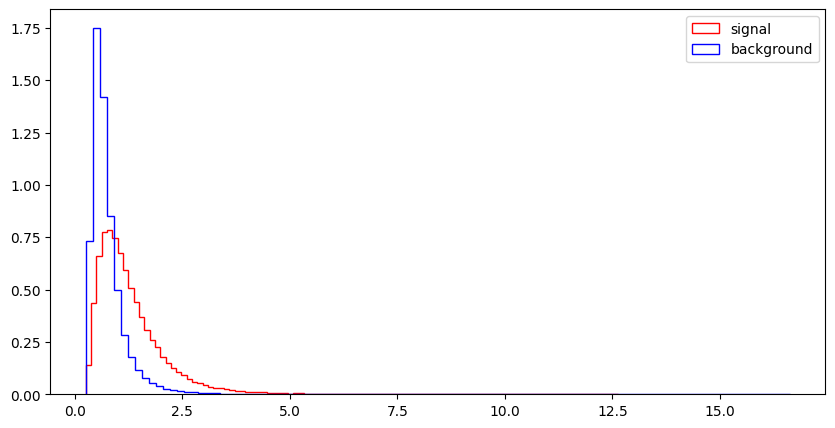

l_1_eta


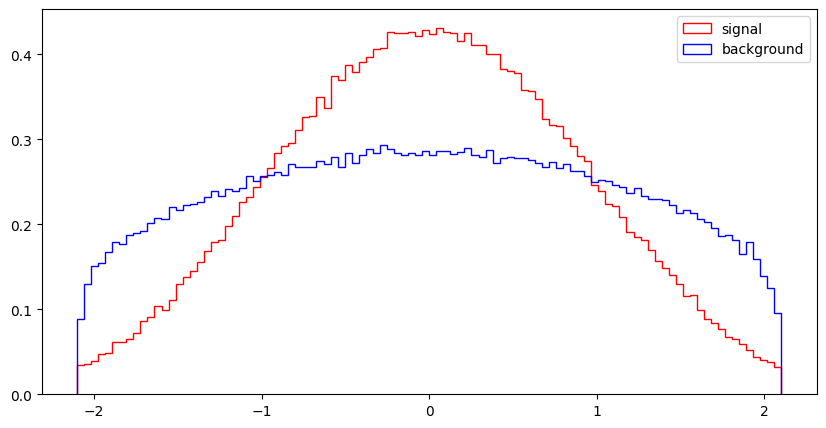

l_1_phi


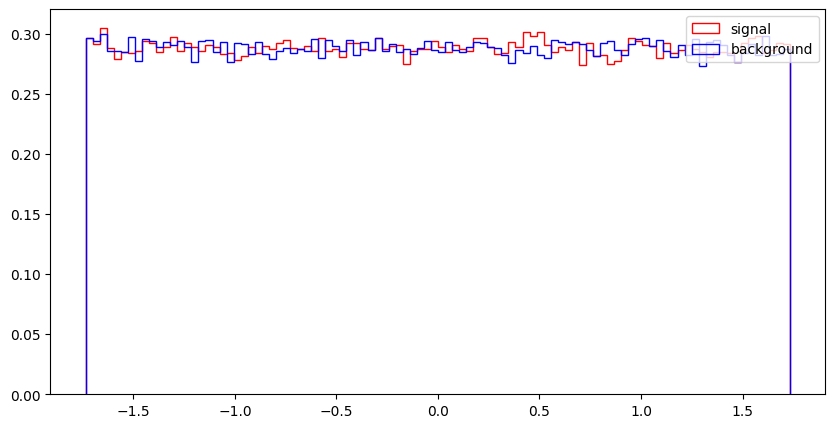

l_2_pT


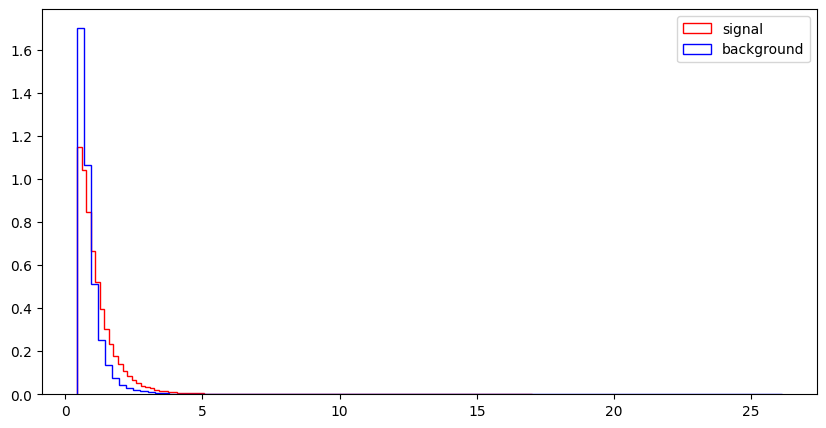

l_2_eta


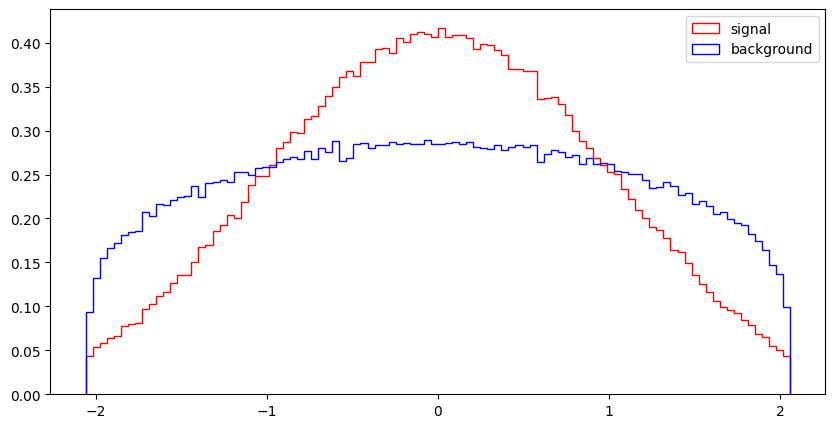

l_2_phi


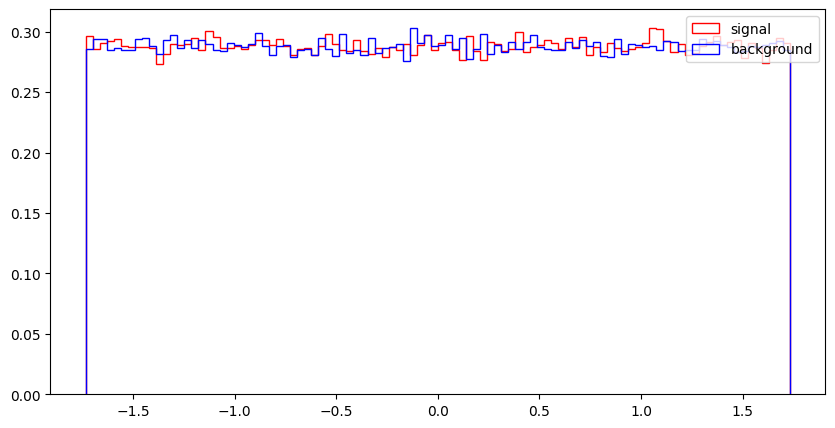

MET


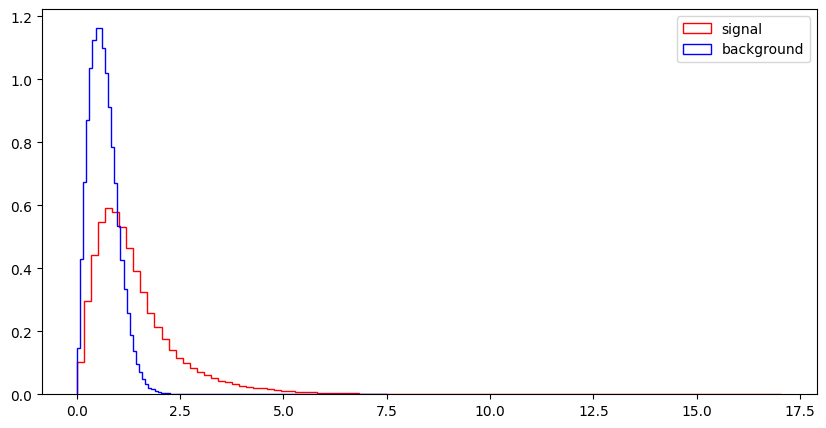

MET_phi


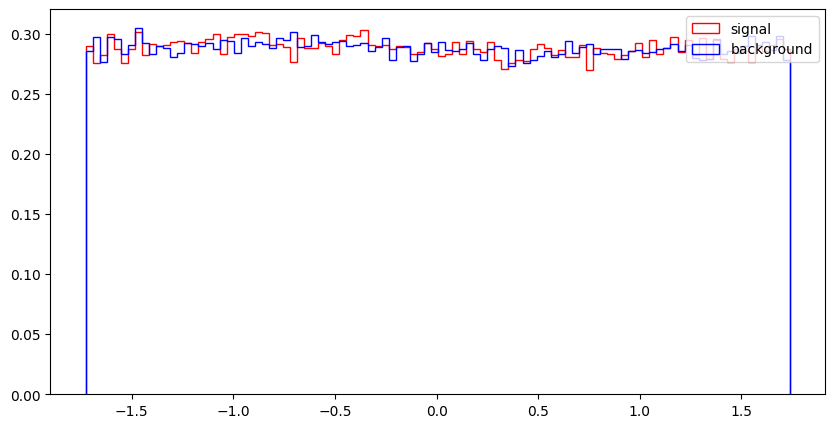

MET_rel


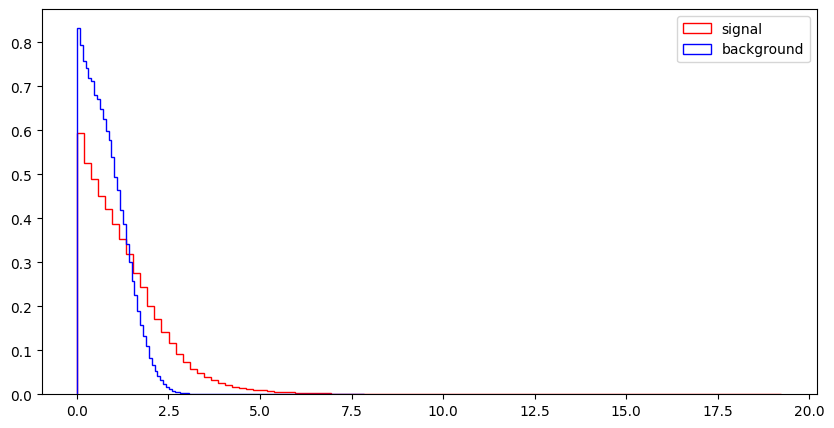

axial_MET


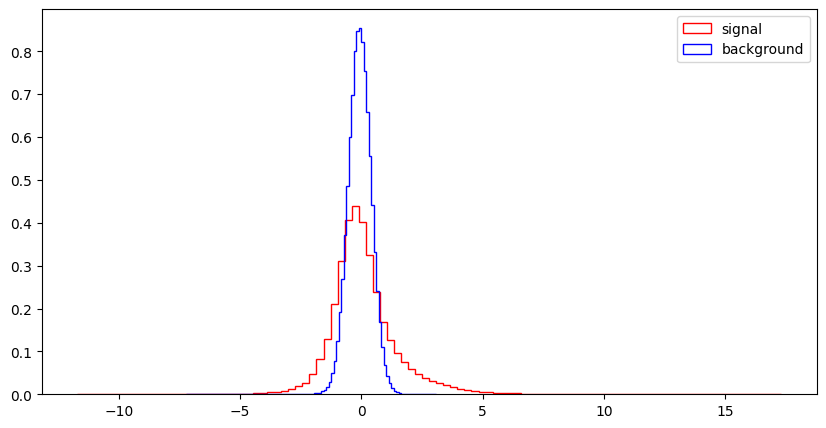

M_R


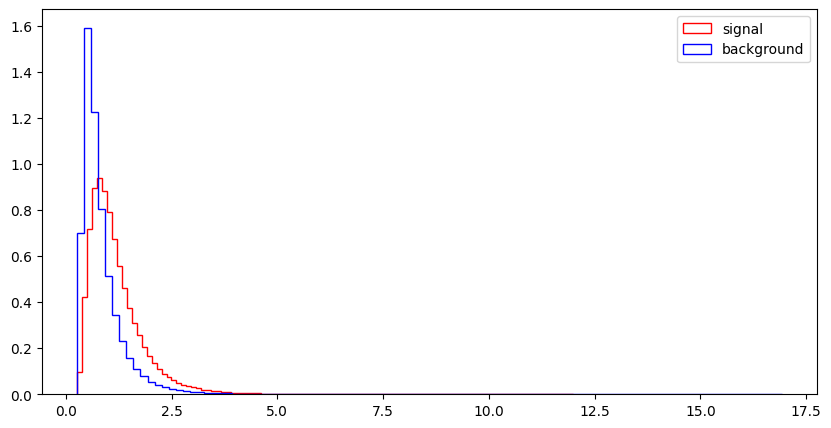

M_TR_2


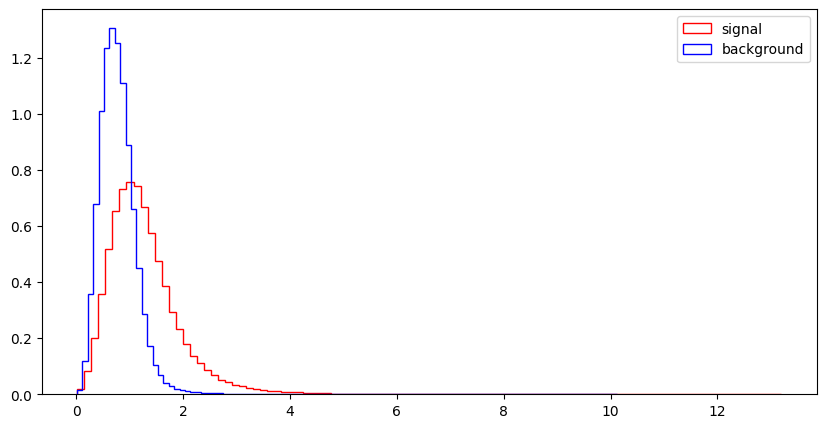

R


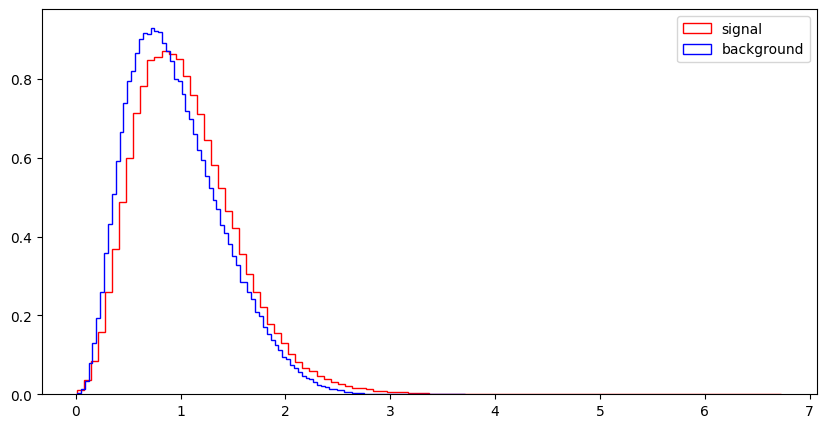

MT2


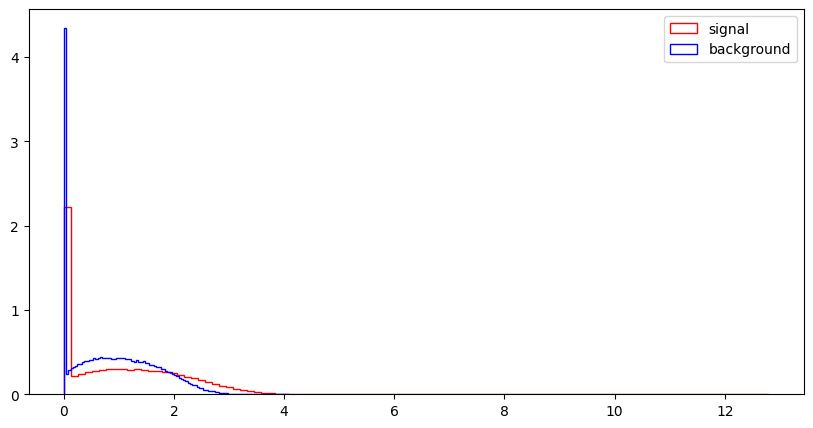

S_R


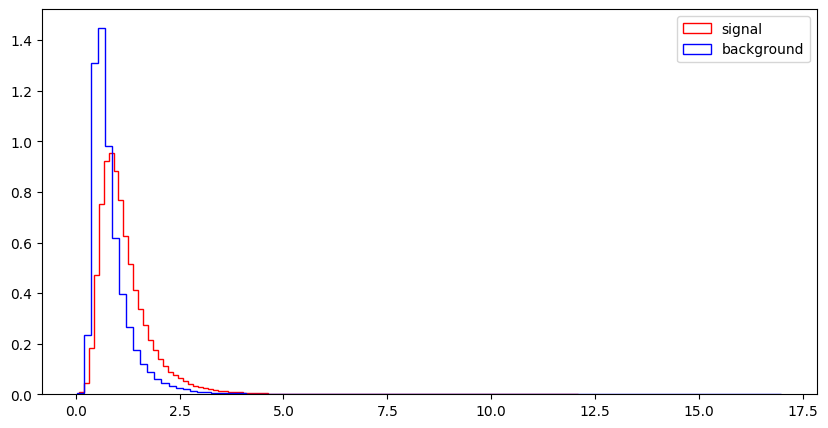

M_Delta_R


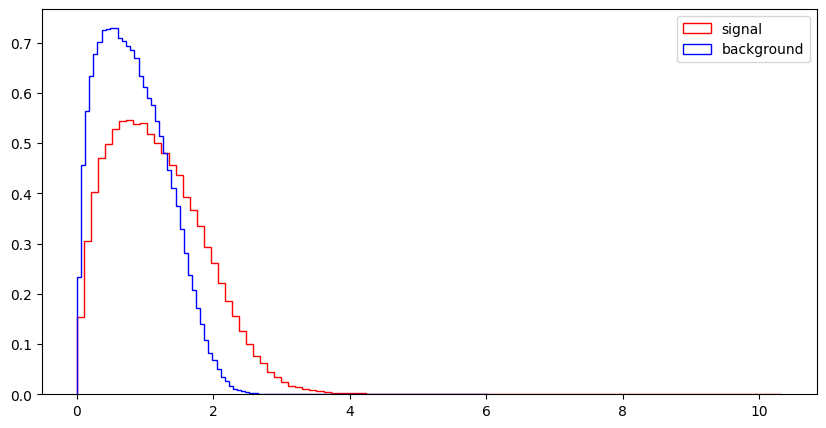

dPhi_r_b


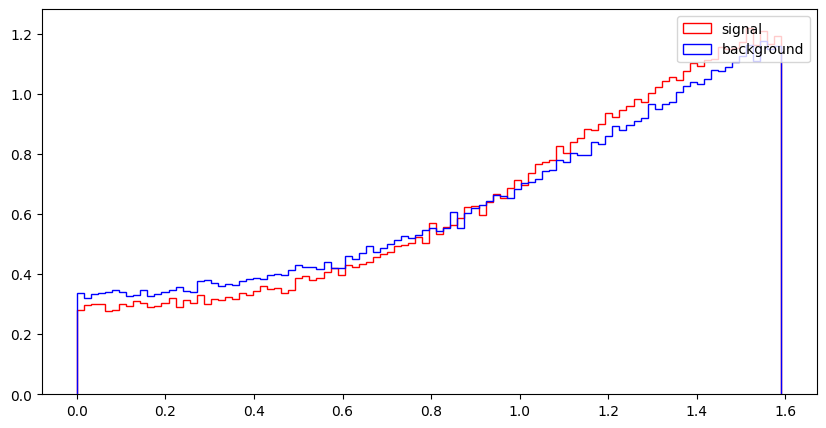

cos_theta_r1


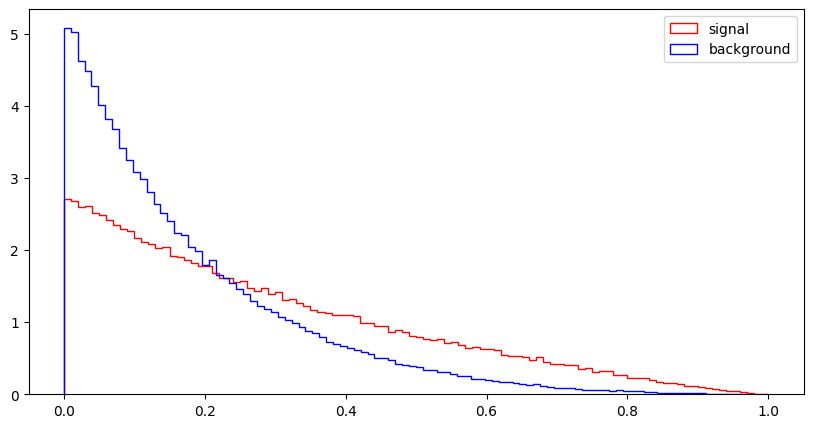

In [70]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

In [71]:
import numpy as np
import matplotlib.pyplot as plt

def make_figure(variables, rows, cols, title):

    fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows))
    axes = axes.flatten()

    for i, var in enumerate(variables):
        ax = axes[i]

        signal = df_sig[var].to_numpy()
        background = df_bkg[var].to_numpy()

        low, high = np.percentile(df[var], [0.5, 99.5])
        bins = np.linspace(low, high, 41)

        ax.hist(signal, bins=bins, histtype="step",
                color="black", label="Signal",
                weights=np.ones(len(signal)) / len(signal))

        ax.hist(background, bins=bins, histtype="step",
                color="red", linestyle="--",
                label="Background",
                weights=np.ones(len(background)) / len(background))

        ax.set_title(var)
        ax.set_xlabel(var)
        ax.set_ylabel("Fraction of events / bin")
        ax.legend()

    for ax in axes[len(variables):]:
        ax.axis("off")

    fig.suptitle(title, fontsize=16)
    fig.tight_layout()
    plt.show()

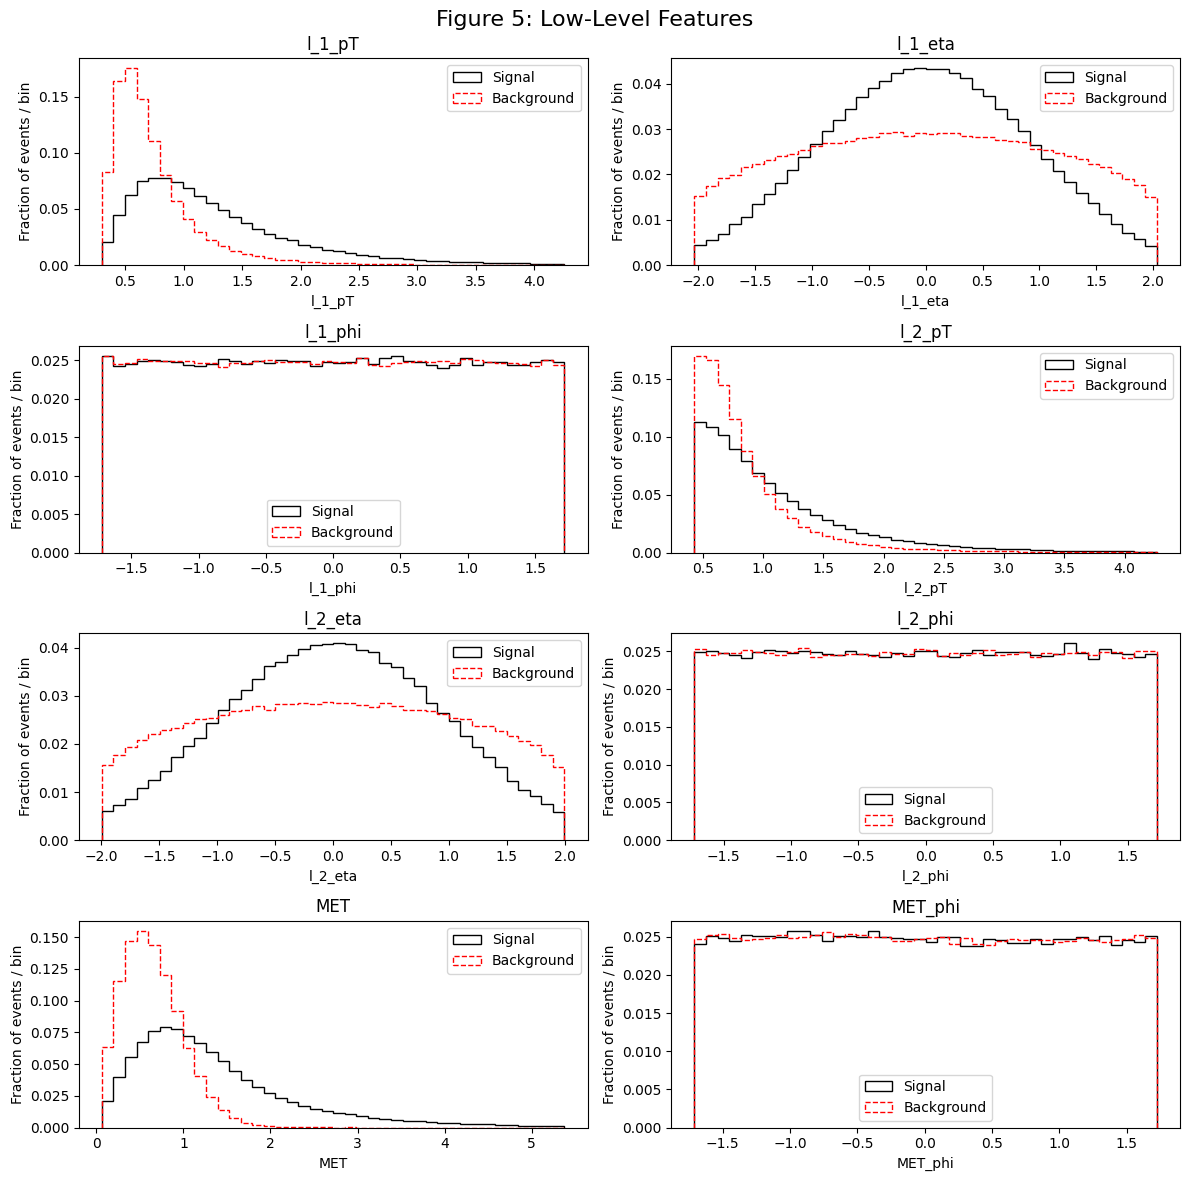

In [72]:
make_figure(RawNames, 4, 2, "Figure 5: Low-Level Features")

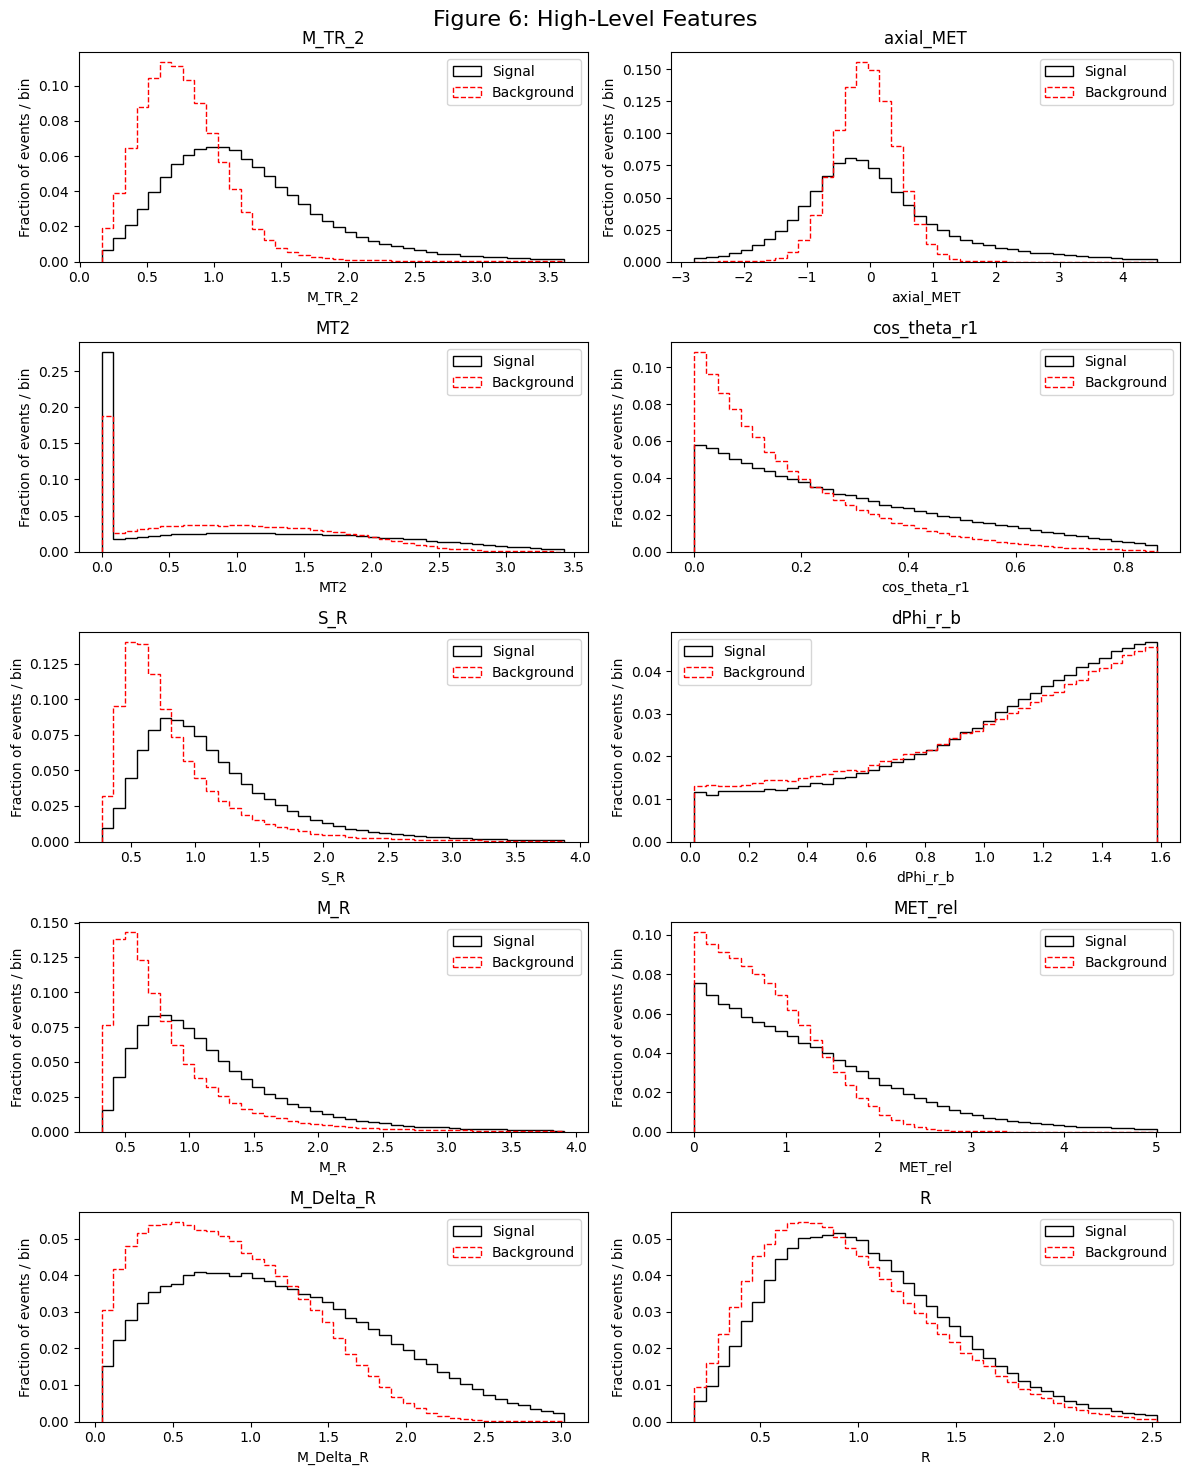

In [73]:
make_figure(FeatureNames, 5, 2, "Figure 6: High-Level Features")

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

In [74]:
# 4.1.a

def pair_plot(columns, sample_size=1000):
    sig = df_sig.sample(
        n=min(sample_size, len(df_sig)),
        random_state=42
    )
    bkg = df_bkg.sample(
        n=min(sample_size, len(df_bkg)),
        random_state=42
    )

    n = len(columns)

    fig, axes = plt.subplots(n, n, figsize=(2*n, 2*n))

    for i, y in enumerate(columns):
        for j, x in enumerate(columns):
            ax = axes[i, j]

            if i == j:
                ax.hist(sig[x], bins=30, histtype="step",
                        color="red", density=True)

                ax.hist(bkg[x], bins=30, histtype="step",
                        color="blue", density=True)

            else:
                # Scatter plots for variable pairs
                ax.scatter(sig[x], sig[y],
                           s=2, alpha=0.3, color="red")

                ax.scatter(bkg[x], bkg[y],
                           s=2, alpha=0.3, color="blue")

            if i == n-1:
                ax.set_xlabel(x, fontsize=8)

            if j == 0:
                ax.set_ylabel(y, fontsize=8)

            ax.tick_params(labelsize=6)

    plt.tight_layout()
    plt.show()

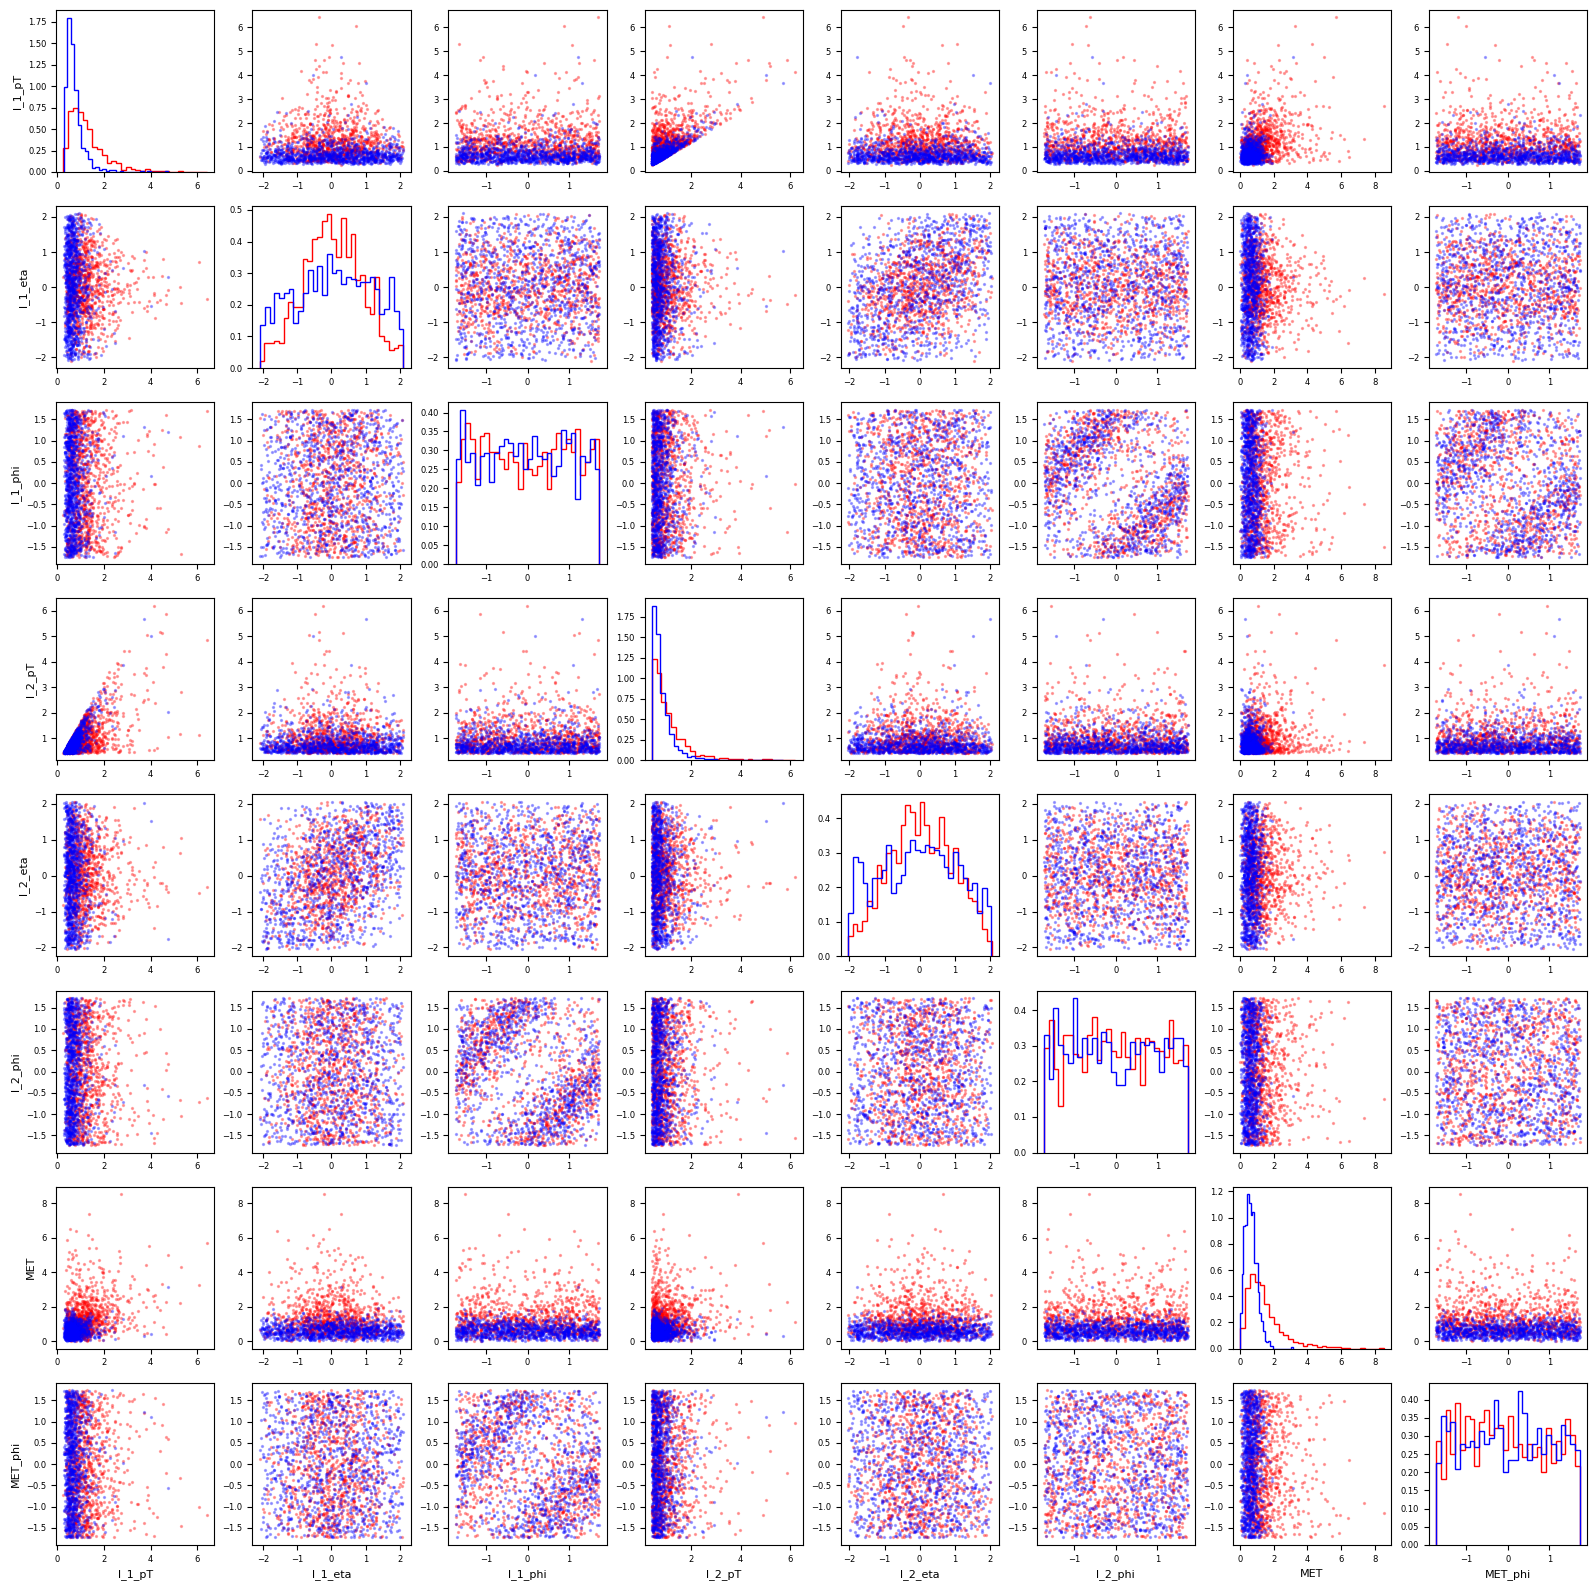

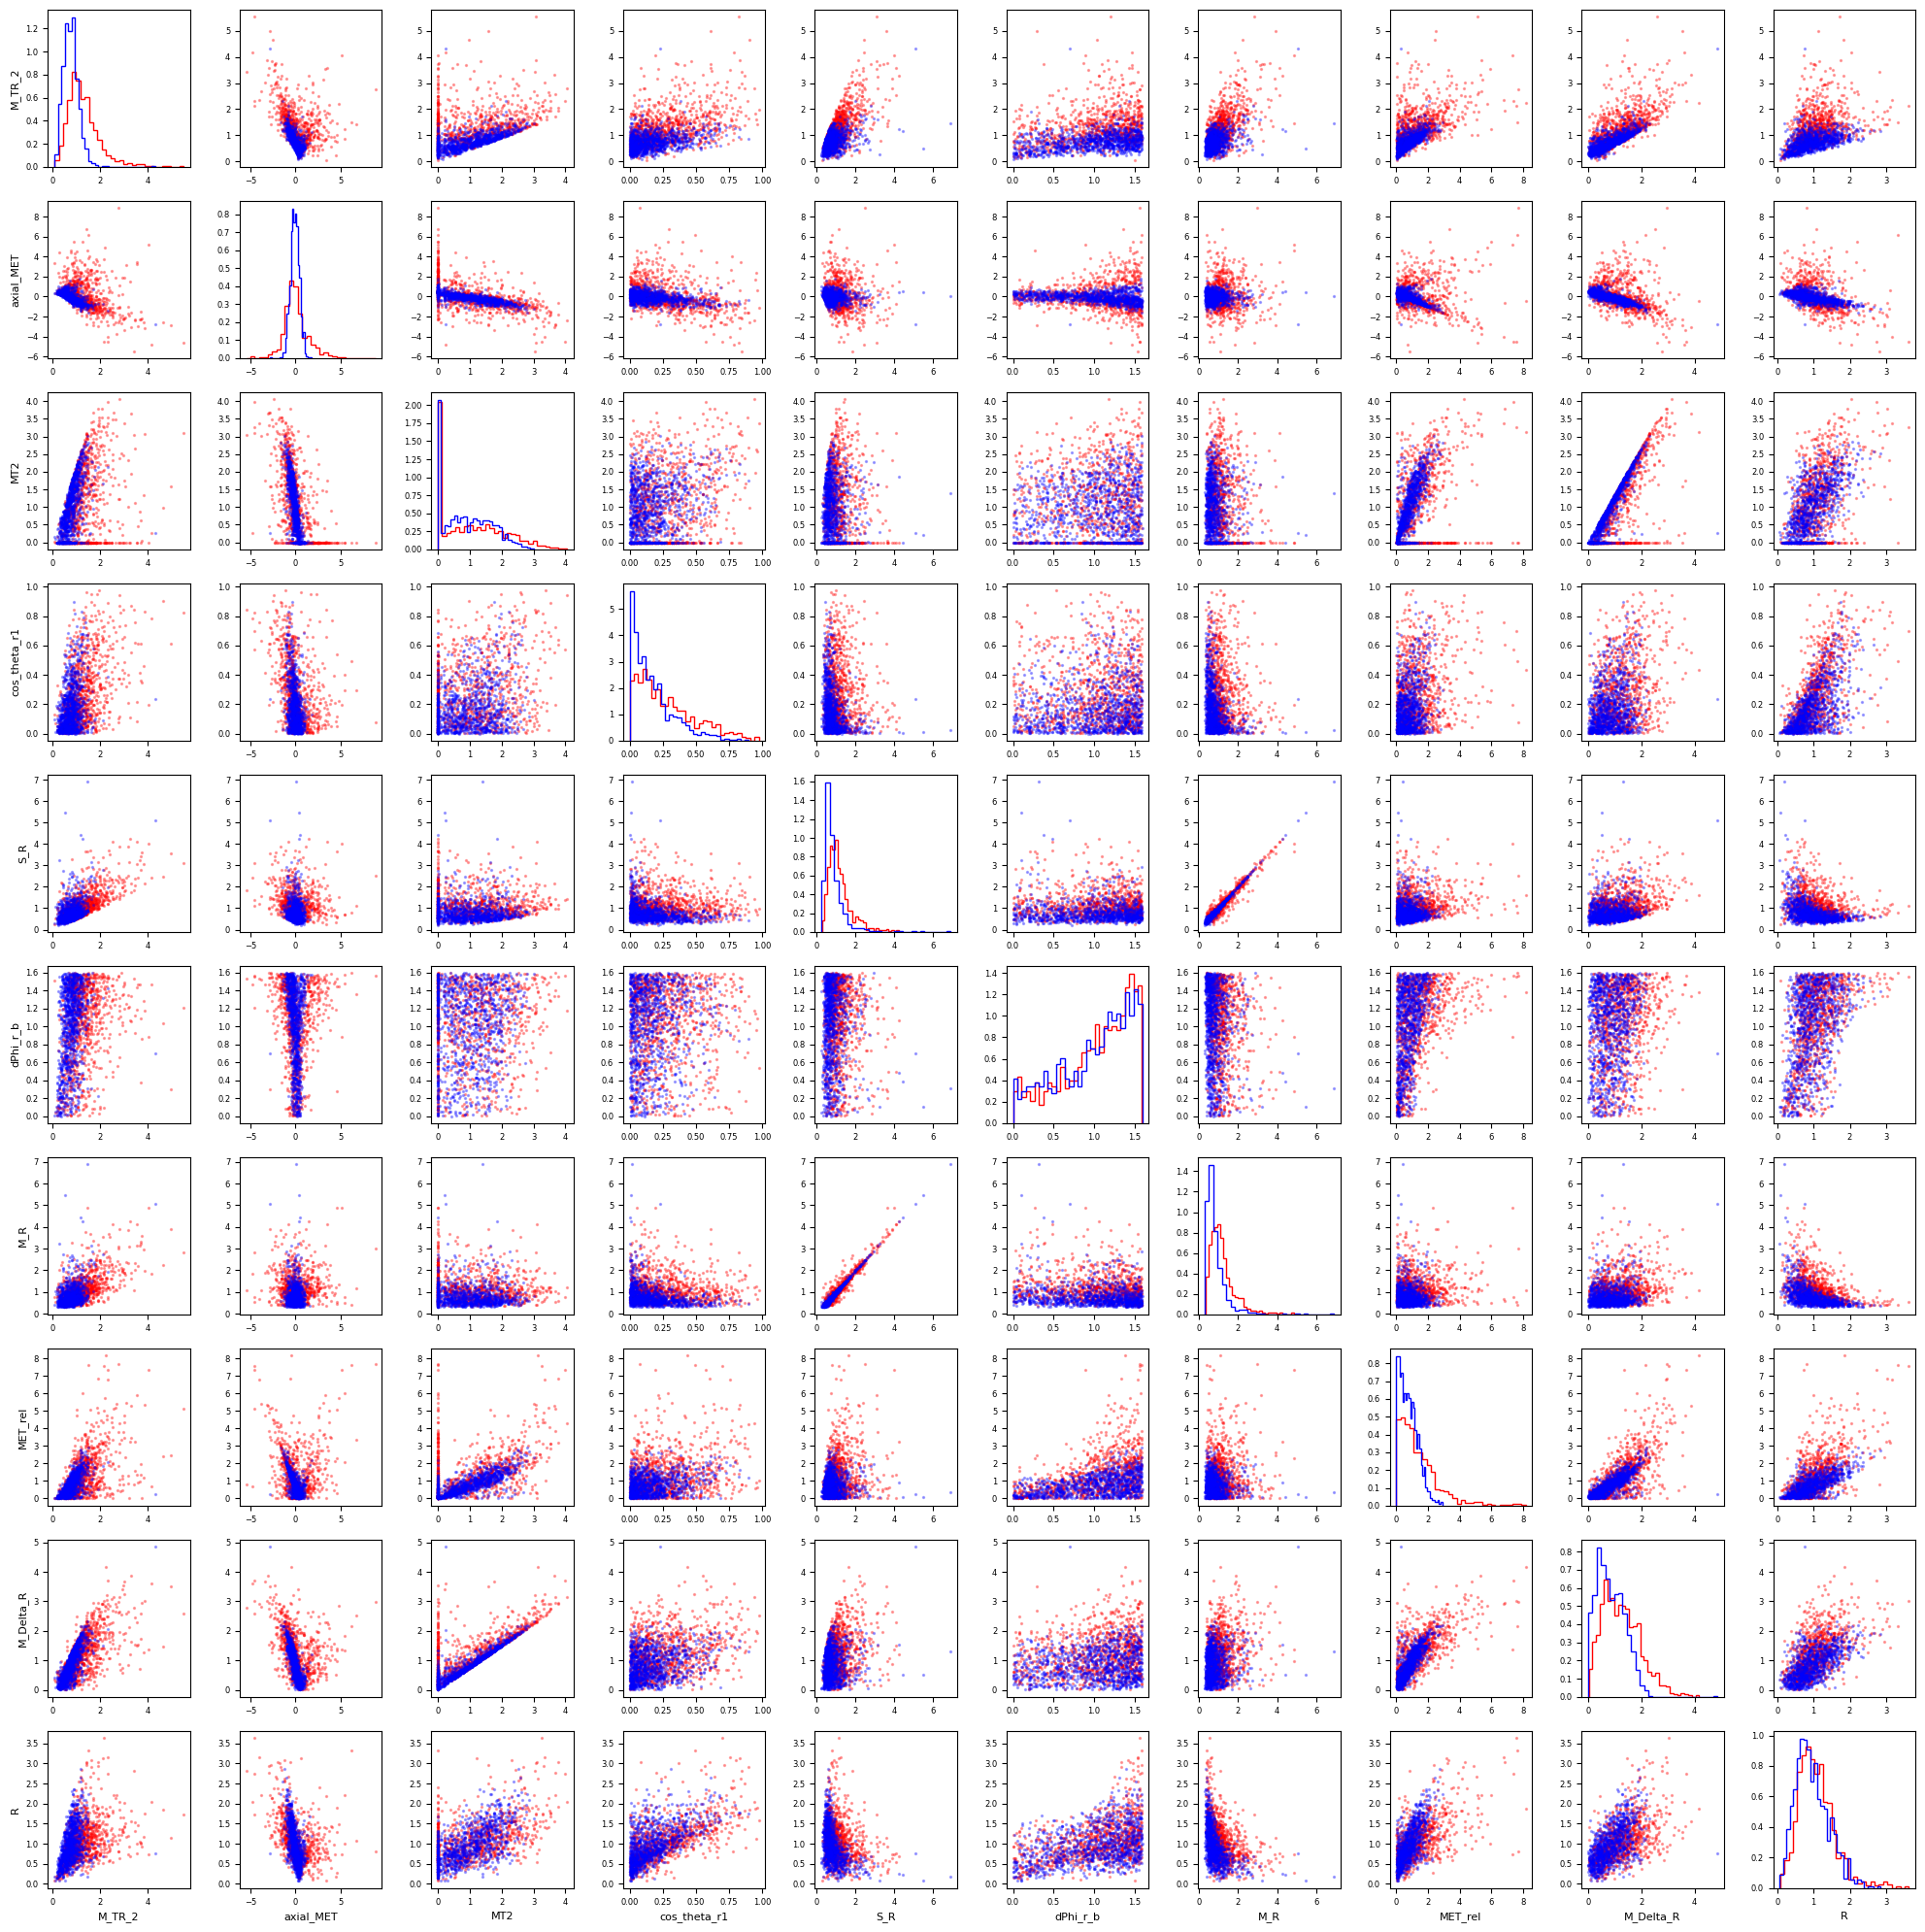

In [75]:
pair_plot(RawNames)
pair_plot(FeatureNames)

In [76]:
# 4.1.b
sig = df_sig.sample(n=1000, random_state=42)
bkg = df_bkg.sample(n=1000, random_state=42)


# randomly sampling events from each class isntead of plotting all 500,000 events will improve the function. 

In [77]:
# 4.1.c

# l_1_eta, l_2<eta, and MET

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [78]:
%pip install tabulate

You should consider upgrading via the '/Users/doodles/Data-3402/jupyter-env/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [82]:
import numpy as np
import tabulate
from IPython.display import HTML, display

In [85]:
all_variables = VarNames[1:]

cov_all = np.cov(df[all_variables], rowvar=False)
corr_all = np.corrcoef(df[all_variables], rowvar=False)

cov_raw = np.cov(df[RawNames], rowvar=False)
corr_raw = np.corrcoef(df[RawNames], rowvar=False)

cov_high = np.cov(df[FeatureNames], rowvar=False)
corr_high = np.corrcoef(df[FeatureNames], rowvar=False)

In [86]:
feature_data = df[FeatureNames]

cov_features = np.cov(feature_data, rowvar=False)
corr_features = np.corrcoef(feature_data, rowvar=False)

In [87]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

X,Y,Z
A,1,2
C,3,4
D,5,6


In [88]:
def show_matrices(dataset, variables, title):
    data = dataset[variables].to_numpy()

    covariance = np.cov(data, rowvar=False)
    correlation = np.corrcoef(data, rowvar=False)

    def make_table(matrix, heading, fmt):
        table = []

        for i, name in enumerate(variables):
            row = [name]

            for value in matrix[i]:
                row.append(format(value, fmt))

            table.append(row)

        headers = ["Variable"] + list(variables)

        html = tabulate.tabulate(
            table,
            headers=headers,
            tablefmt="html"
        )

        display(HTML(
            f"<h3>{title}: {heading}</h3>"
            f"<div style='overflow-x:auto'>{html}</div>"
        ))

    make_table(covariance, "Covariance Matrix", ".3g")

    make_table(correlation, "Correlation Matrix", ".3f")

    return covariance, correlation

In [89]:
cov_all, corr_all = show_matrices(
    df, VarNames[1:], "All Observables"
)

Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937,0.0975,-0.00973,0.364,0.287,-0.0597,-0.0124,0.343,0.0977,-0.0469,0.0222
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589,-0.00137,-0.00111,-0.000554,-0.000669,0.000301,0.000427,-0.000604,-0.000987,-0.00074,0.000322
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185,0.000706,-0.00187,0.00106,0.000869,0.000202,0.00106,0.00146,0.000901,0.000994,0.000259
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156,-0.000534,0.0513,0.325,0.163,-0.0994,-0.0689,0.322,0.00572,-0.00383,-0.0279
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322,0.00108,-0.000756,-0.000608,1.89e-05,0.000321,0.0014,-0.000679,0.00067,-0.000307,0.000296
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354,0.00145,-0.0018,0.00076,0.000509,0.000551,0.00226,0.000906,0.00133,-0.000241,3.7e-05
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.0731
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1,-0.0049,-0.000442,-0.00148,-0.0012,-0.00023,8.39e-05,-0.00171,-0.00057,-0.00171,0.000119
MET_rel,0.0975,-0.00137,0.000706,-0.000534,0.00108,0.00145,0.546,-0.0049,0.79,-0.12,0.0437,0.302,0.249,0.409,0.0823,0.415,0.146,0.0553
axial_MET,-0.00973,-0.00111,-0.00187,0.0513,-0.000756,-0.0018,0.154,-0.000442,-0.12,1.01,0.0171,-0.185,-0.181,-0.461,-0.0414,-0.233,-0.0251,-0.0537


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001,0.16,-0.014,0.851,0.723,-0.186,-0.021,0.811,0.229,-0.157,0.165
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001,-0.002,-0.001,-0.001,-0.001,0.001,0,-0.001,-0.002,-0.002,0.002
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184,0.001,-0.002,0.002,0.001,0,0.001,0.002,0.001,0.002,0.001
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002,-0.001,0.078,0.797,0.43,-0.324,-0.123,0.799,0.014,-0.013,-0.217
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0,0.001,-0.001,-0.001,0,0.001,0.002,-0.001,0.001,-0.001,0.001
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035,0.002,-0.002,0.001,0.001,0.001,0.003,0.001,0.002,-0.001,0
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003,0.704,0.176,0.264,0.72,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1,-0.005,-0,-0.002,-0.002,-0,0,-0.003,-0.001,-0.004,0.001
MET_rel,0.16,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.014,-0.001,-0.002,0.078,-0.001,-0.002,0.176,-0,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272


In [90]:
cov_raw, corr_raw = show_matrices(
    df, RawNames, "Low-Level Features"
)

Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0.000397,7.66e-05,0.305,-0.000349,0.000737,0.228,-0.000937
l_1_eta,-0.000397,1,-0.000858,-0.000163,0.408,-0.00104,-0.00215,-0.000589
l_1_phi,7.66e-05,-0.000858,1,0.00131,0.000251,-0.267,0.000766,-0.185
l_2_pT,0.305,-0.000163,0.00131,0.425,-0.000576,0.000156,0.0795,-0.00156
l_2_eta,-0.000349,0.408,0.000251,-0.000576,1.01,0.000442,0.000382,-0.000322
l_2_phi,0.000737,-0.00104,-0.267,0.000156,0.000442,1,-0.000304,-0.0354
MET,0.228,-0.00215,0.000766,0.0795,0.000382,-0.000304,0.762,-0.00279
MET_phi,-0.000937,-0.000589,-0.185,-0.00156,-0.000322,-0.0354,-0.00279,1


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1


In [91]:
cov_high, corr_high = show_matrices(
    df, FeatureNames, "High-Level Features"
)


Variable,M_TR_2,axial_MET,MT2,cos_theta_r1,S_R,dPhi_r_b,M_R,MET_rel,M_Delta_R,R
M_TR_2,0.338,-0.185,0.189,0.0517,0.228,0.0581,0.21,0.302,0.242,0.104
axial_MET,-0.185,1.01,-0.461,-0.0537,-0.0414,-0.0251,0.0171,-0.12,-0.233,-0.181
MT2,0.189,-0.461,0.738,0.0446,-0.011,0.0209,-0.0365,0.409,0.433,0.232
cos_theta_r1,0.0517,-0.0537,0.0446,0.0388,-0.0104,0.00908,-0.0143,0.0553,0.0392,0.0582
S_R,0.228,-0.0414,-0.011,-0.0104,0.382,-0.00346,0.38,0.0823,0.0958,-0.0834
dPhi_r_b,0.0581,-0.0251,0.0209,0.00908,-0.00346,0.19,-0.029,0.146,0.0422,0.0871
M_R,0.21,0.0171,-0.0365,-0.0143,0.38,-0.029,0.392,0.0437,0.0739,-0.113
MET_rel,0.302,-0.12,0.409,0.0553,0.0823,0.146,0.0437,0.79,0.415,0.249
M_Delta_R,0.242,-0.233,0.433,0.0392,0.0958,0.0422,0.0739,0.415,0.389,0.165
R,0.104,-0.181,0.232,0.0582,-0.0834,0.0871,-0.113,0.249,0.165,0.222


Variable,M_TR_2,axial_MET,MT2,cos_theta_r1,S_R,dPhi_r_b,M_R,MET_rel,M_Delta_R,R
M_TR_2,1,-0.317,0.379,0.451,0.635,0.229,0.577,0.584,0.668,0.38
axial_MET,-0.317,1,-0.535,-0.272,-0.067,-0.057,0.027,-0.134,-0.373,-0.383
MT2,0.379,-0.535,1,0.264,-0.021,0.056,-0.068,0.535,0.809,0.574
cos_theta_r1,0.451,-0.272,0.264,1,-0.085,0.106,-0.116,0.316,0.319,0.627
S_R,0.635,-0.067,-0.021,-0.085,1,-0.013,0.981,0.15,0.249,-0.287
dPhi_r_b,0.229,-0.057,0.056,0.106,-0.013,1,-0.106,0.378,0.155,0.424
M_R,0.577,0.027,-0.068,-0.116,0.981,-0.106,1,0.078,0.189,-0.383
MET_rel,0.584,-0.134,0.535,0.316,0.15,0.378,0.078,1,0.748,0.595
M_Delta_R,0.668,-0.373,0.809,0.319,0.249,0.155,0.189,0.748,1,0.564
R,0.38,-0.383,0.574,0.627,-0.287,0.424,-0.383,0.595,0.564,1


## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

In [92]:
# 5.1

#l_1_pT, 1
#l_1_eta, 4 
#l_1_phi, not useful
#l_2_pT, 1
#l_2_eta, 4
#l_2_phi, not useful
#MET, 1
#MET_phi, not an useful cut
#M_TR_2, 1
#axial_MET, 3
#MT2 1
#cos_theta_r1, 1
#S_R, 1
#dPhi_r_b, 2
#M_R, 1
#MET_rel, 1 
#M_Delta_R, 1
#R, 1

In [95]:
# oh, this is what i was supposed to do...

cut_rules = {
    "l_1_pT": "gt",
    "l_1_eta": "abs_lt",
    "l_1_phi": "gt",
    "l_2_pT": "gt",
    "l_2_eta": "abs_lt",
    "l_2_phi": "gt",
    "MET": "gt",
    "MET_phi": "gt",
    "MET_rel": "gt",
    "axial_MET": "abs_gt",
    "M_R": "gt",
    "M_TR_2": "gt",
    "R": "gt",
    "MT2": "gt",
    "S_R": "gt",
    "M_Delta_R": "gt",
    "dPhi_r_b": "lt",
    "cos_theta_r1": "gt"
}

In [97]:
# 5.2

import numpy as np
import matplotlib.pyplot as plt

def efficiency_curves(var, n_points=201):
    rule = cut_rules[var]

    sig = df_sig[var].to_numpy()
    bkg = df_bkg[var].to_numpy()

    if rule.startswith("abs"):
        sig = np.abs(sig)
        bkg = np.abs(bkg)

    sig = np.sort(sig)
    bkg = np.sort(bkg)

    all_values = np.concatenate((sig, bkg))

    cutoffs = np.unique(np.r_[
        np.nextafter(all_values.min(), -np.inf),
        np.quantile(all_values, np.linspace(0, 1, n_points)),
        np.nextafter(all_values.max(), np.inf)
    ])

    if rule in ("gt", "abs_gt"):
        # Keep values greater than the cutoff
        eff_s = (
            len(sig) - np.searchsorted(sig, cutoffs, side="right")
        ) / len(sig)

        eff_b = (
            len(bkg) - np.searchsorted(bkg, cutoffs, side="right")
        ) / len(bkg)

    else:
        eff_s = (
            np.searchsorted(sig, cutoffs, side="left")
        ) / len(sig)

        eff_b = (
            np.searchsorted(bkg, cutoffs, side="left")
        ) / len(bkg)

    return cutoffs, eff_s, eff_b


curves = {
    var: efficiency_curves(var)
    for var in VarNames[1:]
}

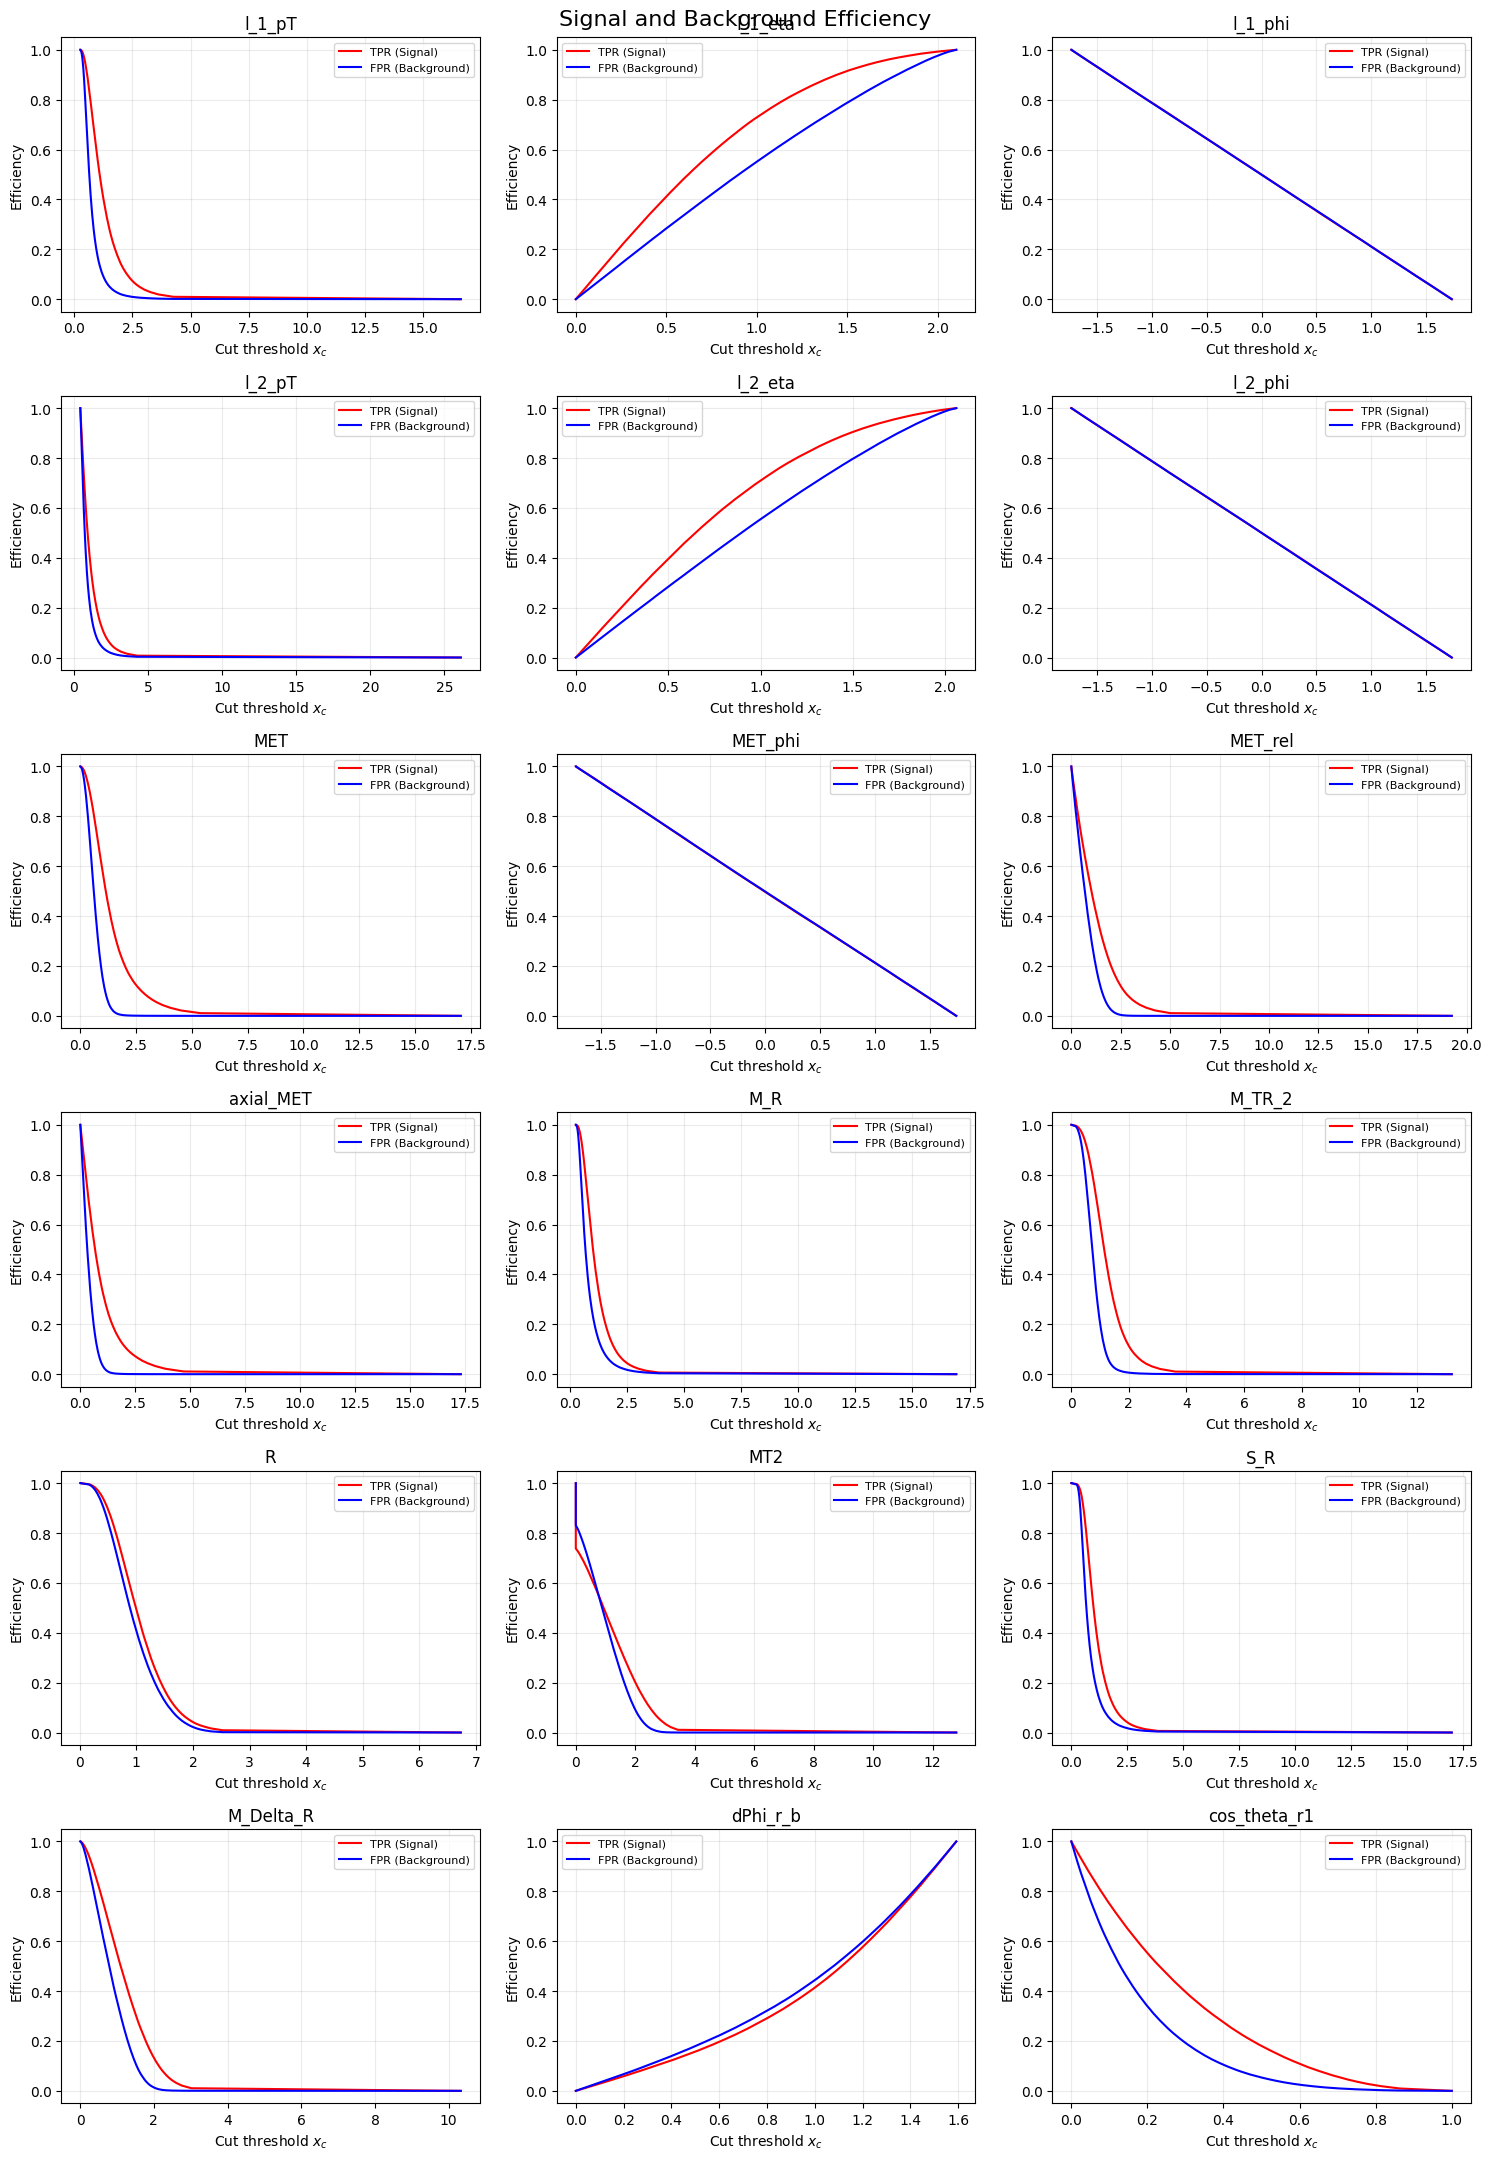

In [98]:
fig, axes = plt.subplots(6, 3, figsize=(15, 22))

for ax, var in zip(axes.flat, VarNames[1:]):
    cutoffs, eff_s, eff_b = curves[var]

    ax.plot(cutoffs, eff_s,
            color="red", label="TPR (Signal)")

    ax.plot(cutoffs, eff_b,
            color="blue", label="FPR (Background)")

    ax.set_title(var)
    ax.set_xlabel("Cut threshold $x_c$")
    ax.set_ylabel("Efficiency")
    ax.set_ylim(-0.05, 1.05)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

fig.suptitle("Signal and Background Efficiency", fontsize=16)
fig.tight_layout()
plt.show()

In [101]:
# 5.3
scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

def significance(eff_s, eff_b, N_S, N_B):
    N_S_prime = eff_s * N_S
    N_B_prime = eff_b * N_B

    denominator = np.sqrt(N_S_prime + N_B_prime)

    return np.divide(
        N_S_prime,
        denominator,
        out=np.zeros_like(N_S_prime, dtype=float),
        where=denominator > 0
    )

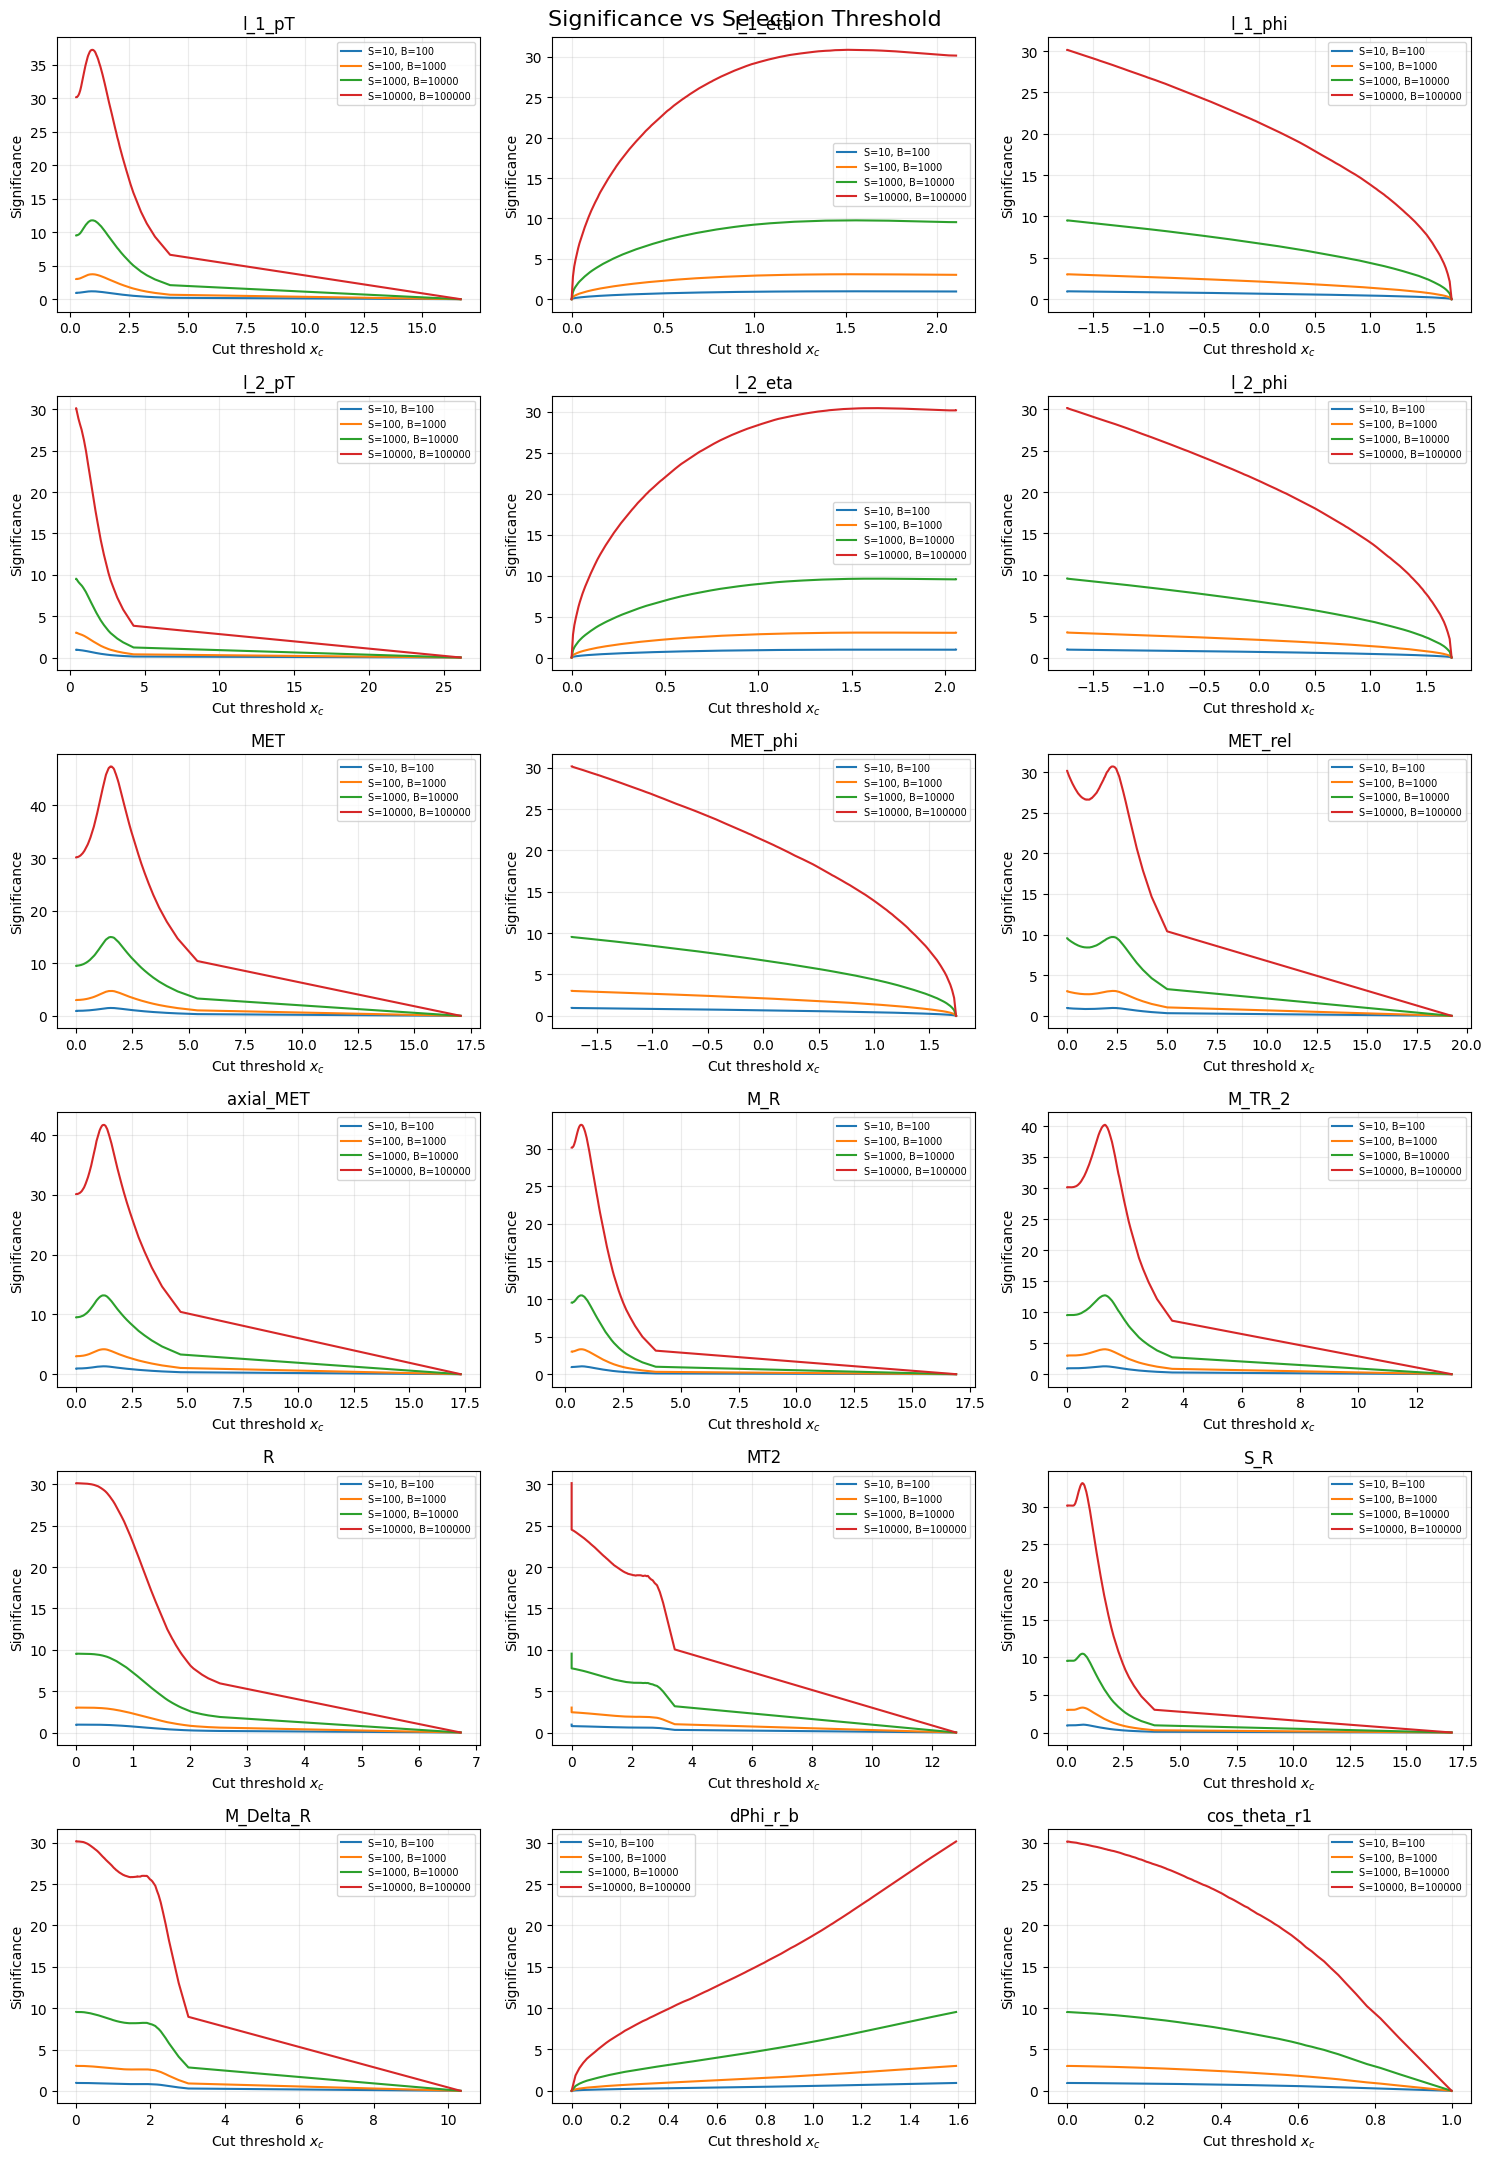

In [102]:
fig, axes = plt.subplots(6, 3, figsize=(15, 22))

for ax, var in zip(axes.flat, VarNames[1:]):
    cutoffs, eff_s, eff_b = curves[var]

    for N_S, N_B in scenarios:
        sigma = significance(eff_s, eff_b, N_S, N_B)

        ax.plot(
            cutoffs,
            sigma,
            label=f"S={N_S}, B={N_B}"
        )

    ax.set_title(var)
    ax.set_xlabel("Cut threshold $x_c$")
    ax.set_ylabel("Significance")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.25)

fig.suptitle("Significance vs Selection Threshold", fontsize=16)
fig.tight_layout()
plt.show()

In [103]:
from IPython.display import display

results = []

for var in VarNames[1:]:
    cutoffs, eff_s, eff_b = curves[var]

    sigma = significance(eff_s, eff_b, 10, 100)
    best_index = np.argmax(sigma)

    best_cut = cutoffs[best_index]

    row = {
        "Observable": var,
        "Selection": cut_rules[var],
        "Best x_c": best_cut,
        "TPR": eff_s[best_index],
        "FPR": eff_b[best_index]
    }

    for N_S, N_B in scenarios:
        value = significance(
            eff_s, eff_b, N_S, N_B
        )

        row[f"Significance {N_S}/{N_B}"] = value[best_index]

    results.append(row)

optimal_cuts = pd.DataFrame(results)

display(optimal_cuts.round(3))

,Observable,Selection,Best x_c,TPR,FPR,Significance 10/100,Significance 100/1000,Significance 1000/10000,Significance 10000/100000
0,l_1_pT,gt,0.959,0.590,0.193,1.177,3.721,11.768,37.213
1,l_1_eta,abs_lt,1.511,0.918,0.792,0.976,3.087,9.761,30.868
2,l_1_phi,gt,-1.735,1.000,1.000,0.953,3.015,9.535,30.151
3,l_2_pT,gt,0.429,1.000,1.000,0.953,3.015,9.535,30.151
4,l_2_eta,abs_lt,1.625,0.935,0.852,0.962,3.043,9.622,30.426
5,l_2_phi,gt,-1.734,1.000,1.000,0.953,3.015,9.535,30.151
6,MET,gt,1.525,0.331,0.016,1.499,4.741,14.992,47.408
7,MET_phi,gt,-1.727,1.000,1.000,0.953,3.015,9.535,30.151
8,MET_rel,gt,2.271,0.152,0.009,0.971,3.070,9.708,30.698
9,axial_MET,abs_gt,1.255,0.249,0.011,1.320,4.173,13.195,41.727


## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




In [105]:
# 6.1
import numpy as np
import pandas as pd
from IPython.display import display

selected_vars = ["MET", "l_1_eta", "M_TR_2"]

selected_cuts = {}

for var in selected_vars:
    row = optimal_cuts[optimal_cuts["Observable"] == var]
    selected_cuts[var] = float(row["Best x_c"].iloc[0])

for var, cutoff in selected_cuts.items():
    print(f"{var}: x_c = {cutoff:.4f}")

MET: x_c = 1.5250
l_1_eta: x_c = 1.5108
M_TR_2: x_c = 1.3054


In [110]:
# 6.

def passes_cut(data, var, cutoff):
    x = data[var].to_numpy()
    rule = cut_rules[var]

    if rule.startswith("abs"):
        x = np.abs(x)

    if rule in ("gt", "abs_gt"):
        return x > cutoff

    if rule in ("lt", "abs_lt"):
        return x < cutoff

    raise ValueError(f"Unknown rule: {rule}")


def cut_flow(variables, cuts, N_S, N_B):

    sig_keep = np.ones(len(df_sig), dtype=bool)
    bkg_keep = np.ones(len(df_bkg), dtype=bool)

    rows = []

    def add_row(label):
        eff_s = sig_keep.sum() / len(df_sig)
        eff_b = bkg_keep.sum() / len(df_bkg)

        S = eff_s * N_S
        B = eff_b * N_B

        sigma = S / np.sqrt(S + B) if S + B > 0 else 0

        rows.append({
            "Cut": label,
            "epsilon_S": eff_s,
            "epsilon_B": eff_b,
            "N'_S": S,
            "N'_B": B,
            "Significance": sigma
        })

    add_row("No cuts")

    for var in variables:
        cutoff = cuts[var]

        sig_keep &= passes_cut(df_sig, var, cutoff)
        bkg_keep &= passes_cut(df_bkg, var, cutoff)

        add_row(f"{var}: {cut_rules[var]} {cutoff:.3f}")

    return pd.DataFrame(rows)

for N_S, N_B in scenarios:

    print(f"\nScenario: N_S={N_S}, N_B={N_B}")

    table = cut_flow(
        selected_vars,
        selected_cuts,
        N_S,
        N_B
    )

    display(table.round(4))


Scenario: N_S=10, N_B=100


,Cut,epsilon_S,epsilon_B,N'_S,N'_B,Significance
0,No cuts,1.0000,1.0000,10.0000,100.0000,0.9535
1,MET: gt 1.525,0.3306,0.0156,3.3059,1.5568,1.4992
2,l_1_eta: abs_lt 1.511,0.3085,0.0126,3.0847,1.2624,1.4795
3,M_TR_2: gt 1.305,0.2260,0.0093,2.2596,0.9296,1.2653



Scenario: N_S=100, N_B=1000


,Cut,epsilon_S,epsilon_B,N'_S,N'_B,Significance
0,No cuts,1.0000,1.0000,100.0000,1000.0000,3.0151
1,MET: gt 1.525,0.3306,0.0156,33.0585,15.5676,4.7408
2,l_1_eta: abs_lt 1.511,0.3085,0.0126,30.8473,12.6240,4.6786
3,M_TR_2: gt 1.305,0.2260,0.0093,22.5959,9.2962,4.0012



Scenario: N_S=1000, N_B=10000


,Cut,epsilon_S,epsilon_B,N'_S,N'_B,Significance
0,No cuts,1.0000,1.0000,1000.0000,10000.0000,9.5346
1,MET: gt 1.525,0.3306,0.0156,330.5852,155.6758,14.9916
2,l_1_eta: abs_lt 1.511,0.3085,0.0126,308.4735,126.2396,14.7951
3,M_TR_2: gt 1.305,0.2260,0.0093,225.9591,92.9623,12.6528



Scenario: N_S=10000, N_B=100000


,Cut,epsilon_S,epsilon_B,N'_S,N'_B,Significance
0,No cuts,1.0000,1.0000,10000.0000,100000.0000,30.1511
1,MET: gt 1.525,0.3306,0.0156,3305.8518,1556.7580,47.4077
2,l_1_eta: abs_lt 1.511,0.3085,0.0126,3084.7347,1262.3959,46.7861
3,M_TR_2: gt 1.305,0.2260,0.0093,2259.5913,929.6227,40.0118


In [121]:
# 6.3

corr = df[VarNames[1:]].corr()

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

strongest = (
    upper.stack()
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

display(strongest)


print(
    "MET / MET_rel correlation:",
    df["MET"].corr(df["MET_rel"])
)




    


M_R      S_R          0.981155
l_1_pT   M_R          0.851136
         S_R          0.810678
MT2      M_Delta_R    0.808521
l_2_pT   S_R          0.798528
         M_R          0.796679
MET_rel  M_Delta_R    0.748284
l_1_pT   M_TR_2       0.722754
MET      M_TR_2       0.719661
         MET_rel      0.704010
dtype: float64

MET / MET_rel correlation: 0.7040103304846907


In [119]:
def optimize_second(first, second, N_S=10, N_B=100):

    first_cut = float(
        optimal_cuts.loc[
            optimal_cuts["Observable"] == first,
            "Best x_c"
        ].iloc[0]
    )

    sig_mask = passes_cut(df_sig, first, first_cut)
    bkg_mask = passes_cut(df_bkg, first, first_cut)

    sig = df_sig.loc[sig_mask, second].to_numpy()
    bkg = df_bkg.loc[bkg_mask, second].to_numpy()

    rule = cut_rules[second]

    if rule.startswith("abs"):
        sig = np.abs(sig)
        bkg = np.abs(bkg)

    combined = np.concatenate([sig, bkg])

    if len(combined) == 0:
        raise ValueError("No events survived the first cut.")

    cutoffs = np.unique(np.r_[
        np.nextafter(combined.min(), -np.inf),
        np.quantile(combined, np.linspace(0, 1, 201)),
        np.nextafter(combined.max(), np.inf)
    ])

    sig_sorted = np.sort(sig)
    bkg_sorted = np.sort(bkg)

    if rule in ("gt", "abs_gt"):
        n_sig = len(sig) - np.searchsorted(
            sig_sorted, cutoffs, side="right"
        )
        n_bkg = len(bkg) - np.searchsorted(
            bkg_sorted, cutoffs, side="right"
        )
    else:
        n_sig = np.searchsorted(
            sig_sorted, cutoffs, side="left"
        )
        n_bkg = np.searchsorted(
            bkg_sorted, cutoffs, side="left"
        )

    eff_s = n_sig / len(df_sig)
    eff_b = n_bkg / len(df_bkg)

    sigma = significance(eff_s, eff_b, N_S, N_B)

    best = np.argmax(sigma)

    return {
        "First cut": first,
        "First threshold": first_cut,
        "Second cut": second,
        "Optimal second threshold": cutoffs[best],
        "epsilon_S": eff_s[best],
        "epsilon_B": eff_b[best],
        "Significance": sigma[best]
    }

In [120]:
result1 = optimize_second("MET", "MET_rel")

result2 = optimize_second("MET_rel", "MET")

comparison = pd.DataFrame([result1, result2])

display(comparison.round(4))

,First cut,First threshold,Second cut,Optimal second threshold,epsilon_S,epsilon_B,Significance
0,MET,1.5250,MET_rel,0.0000,0.3306,0.0156,1.4992
1,MET_rel,2.2713,MET,1.7184,0.1310,0.0034,1.0207


In [123]:
# 6.3 continued

# correlations between observables can reduce the effectivenness of combining selections cause correlated variables contian overlapping inofmration


## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



In [124]:
# 7.1

import numpy as np
import matplotlib.pyplot as plt

def roc_data(signal_scores, background_scores):
    scores = np.concatenate([signal_scores, background_scores])

    labels = np.concatenate([
        np.ones(len(signal_scores), dtype=int),
        np.zeros(len(background_scores), dtype=int)
    ])

    order = np.argsort(-scores, kind="mergesort")
    scores = scores[order]
    labels = labels[order]

    ends = np.r_[
        np.where(np.diff(scores) != 0)[0],
        len(scores) - 1
    ]

    true_positives = np.cumsum(labels)[ends]
    false_positives = (ends + 1) - true_positives

    tpr = np.r_[0, true_positives / len(signal_scores)]
    fpr = np.r_[0, false_positives / len(background_scores)]

    auc = np.sum(
        np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2
    )

    return fpr, tpr, auc

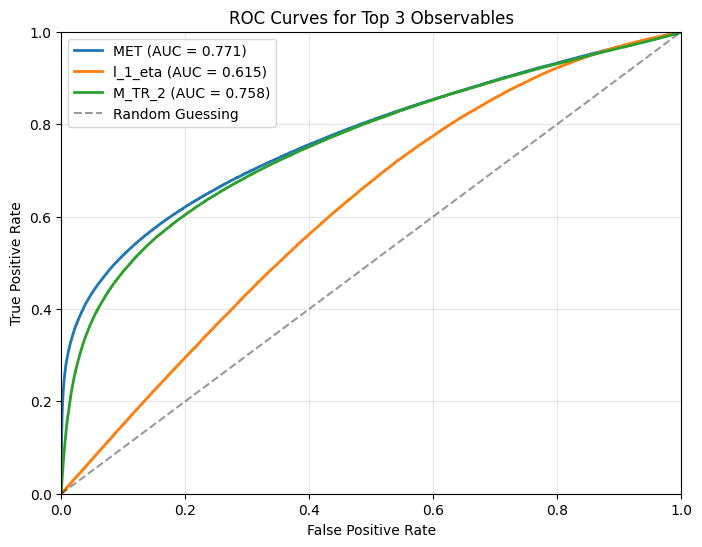

MET: AUC = 0.7710
l_1_eta: AUC = 0.6148
M_TR_2: AUC = 0.7582


In [126]:
# 7.2

def get_scores(data, var):
    rule = cut_rules[var]
    x = data[var].to_numpy()

    if rule.startswith("abs"):
        x = np.abs(x)

    if rule in ("lt", "abs_lt"):
        x = -x

    return x


def plot_roc(variables, prior_cuts=None,
             ax=None, title="ROC Curves",
             cumulative=False):

    if prior_cuts is None:
        prior_cuts = {}

    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 6))

    sig_mask = np.ones(len(df_sig), dtype=bool)
    bkg_mask = np.ones(len(df_bkg), dtype=bool)

    for var, cutoff in prior_cuts.items():
        sig_mask &= passes_cut(df_sig, var, cutoff)
        bkg_mask &= passes_cut(df_bkg, var, cutoff)

    results = {}

    for var in variables:
        sig_scores = get_scores(df_sig.loc[sig_mask], var)
        bkg_scores = get_scores(df_bkg.loc[bkg_mask], var)

        if len(sig_scores) == 0 or len(bkg_scores) == 0:
            print(f"Skipping {var}: one class has no events.")
            continue

        fpr, tpr, auc = roc_data(sig_scores, bkg_scores)
        results[var] = auc

        if cumulative:
            tpr = tpr * sig_mask.mean()
            fpr = fpr * bkg_mask.mean()

            label = f"{var} after {len(prior_cuts)} previous cuts"
        else:
            label = f"{var} (AUC = {auc:.3f})"

        ax.plot(fpr, tpr, linewidth=2, label=label)

    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(title)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()

    return results

top3 = ["MET", "l_1_eta", "M_TR_2"]

fig, ax = plt.subplots(figsize=(8, 6))

auc_results = plot_roc(
    top3,
    ax=ax,
    title="ROC Curves for Top 3 Observables"
)

ax.plot(
    [0, 1], [0, 1],
    "k--", alpha=0.4, label="Random Guessing"
)

ax.legend()
plt.show()

for var, auc in auc_results.items():
    print(f"{var}: AUC = {auc:.4f}")

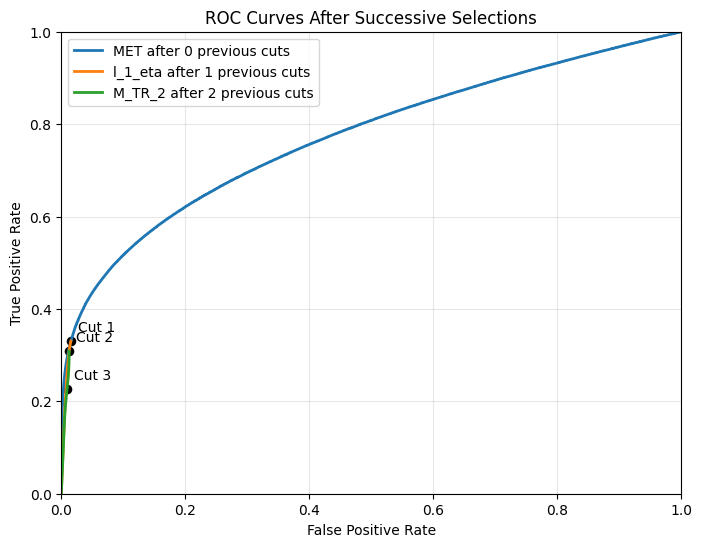

In [128]:
# 7.3

def cumulative_rates(cuts):
    sig_mask = np.ones(len(df_sig), dtype=bool)
    bkg_mask = np.ones(len(df_bkg), dtype=bool)

    for var, cutoff in cuts.items():
        sig_mask &= passes_cut(df_sig, var, cutoff)
        bkg_mask &= passes_cut(df_bkg, var, cutoff)

    return bkg_mask.mean(), sig_mask.mean()


fig, ax = plt.subplots(figsize=(8, 6))

for i, var in enumerate(selected_vars):

    previous = {
        v: selected_cuts[v]
        for v in selected_vars[:i]
    }

    plot_roc(
        [var],
        prior_cuts=previous,
        ax=ax,
        title="ROC Curves After Successive Selections",
        cumulative=True
    )

    current = {
        v: selected_cuts[v]
        for v in selected_vars[:i+1]
    }

    fpr, tpr = cumulative_rates(current)

    ax.scatter(fpr, tpr, color="black", s=35)

    ax.annotate(
        f"Cut {i+1}",
        (fpr, tpr),
        xytext=(5, 7),
        textcoords="offset points"
    )

plt.show()

#

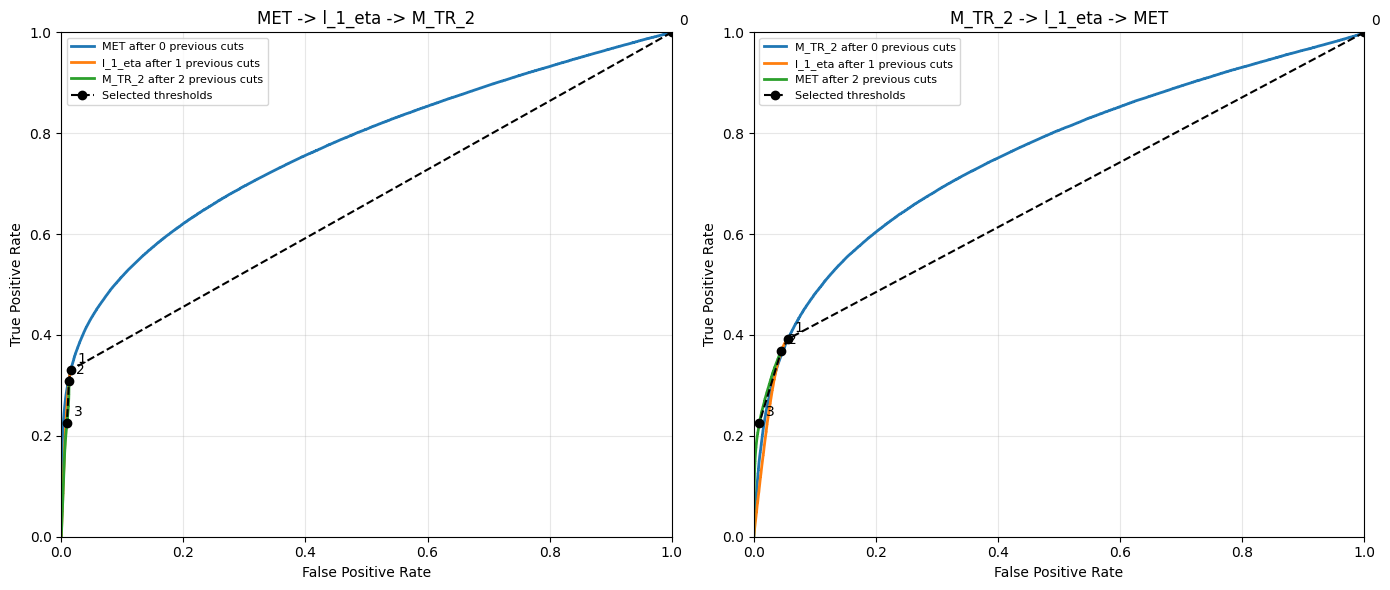

Original order final (FPR, TPR): (np.float64(0.00929622721648723), np.float64(0.22595912669851032))
Reversed order final (FPR, TPR): (np.float64(0.00929622721648723), np.float64(0.22595912669851032))


In [130]:
# 7.4
def plot_selection_order(order, ax):

    fprs = [1.0]
    tprs = [1.0]

    for i, var in enumerate(order):

        previous = {
            v: selected_cuts[v]
            for v in order[:i]
        }

        plot_roc(
            [var],
            prior_cuts=previous,
            ax=ax,
            cumulative=True,
            title=" -> ".join(order)
        )

        current = {
            v: selected_cuts[v]
            for v in order[:i+1]
        }

        fpr, tpr = cumulative_rates(current)

        fprs.append(fpr)
        tprs.append(tpr)

    ax.plot(
        fprs, tprs, "ko--",
        label="Selected thresholds"
    )

    for i, (fpr, tpr) in enumerate(zip(fprs, tprs)):
        ax.annotate(
            str(i), (fpr, tpr),
            xytext=(5, 5),
            textcoords="offset points"
        )

    ax.legend(fontsize=8)

    return fprs[-1], tprs[-1]


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

original = plot_selection_order(
    selected_vars,
    axes[0]
)

reversed_order = plot_selection_order(
    list(reversed(selected_vars)),
    axes[1]
)

plt.tight_layout()
plt.show()

print("Original order final (FPR, TPR):", original)
print("Reversed order final (FPR, TPR):", reversed_order)



In [131]:
result1 = optimize_second("MET", "MET_rel")

result2 = optimize_second("MET_rel", "MET")

print("MET first:")
print(result1)

print("\nMET_rel first:")
print(result2)

MET first:
{'First cut': 'MET', 'First threshold': 1.5250267648696891, 'Second cut': 'MET_rel', 'Optimal second threshold': np.float64(9.238941629519104e-07), 'epsilon_S': np.float64(0.3305851817924055), 'epsilon_B': np.float64(0.015567579546084098), 'Significance': np.float64(1.4991623731290962)}

MET_rel first:
{'First cut': 'MET_rel', 'First threshold': 2.2712590694427486, 'Second cut': 'MET', 'Optimal second threshold': np.float64(1.7184036552906037), 'epsilon_S': np.float64(0.1309690505790748), 'epsilon_B': np.float64(0.003368358848405385), 'Significance': np.float64(1.020667605780282)}


## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

In [132]:
# 8.1

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

variables = VarNames[1:]
X_bkg = df_bkg[variables].to_numpy()
X_sig = df_sig[variables].to_numpy()

m1 = np.mean(X_bkg, axis=0)
m2 = np.mean(X_sig, axis=0)

mean_diff = m2 - m1

S_B = np.outer(mean_diff, mean_diff)

bkg_centered = X_bkg - m1
sig_centered = X_sig - m2

S_W = (
    bkg_centered.T @ bkg_centered
    + sig_centered.T @ sig_centered
)

print("Between-class matrix S_B:")
print(S_B)

print("\nWithin-class matrix S_W:")
print(S_W)

print("\nMatrix dimensions:")
print("S_B:", S_B.shape)
print("S_W:", S_W.shape)

Between-class matrix S_B:
[[ 2.87970231e-01  4.58922304e-04  4.67467434e-04  1.38148662e-01
   1.54068049e-03  3.66095560e-04  4.13461344e-01 -6.36618070e-04
   2.71136238e-01  8.54657090e-02  1.82331687e-01  2.66557653e-01
   5.53227373e-02  7.37824064e-02  1.74241790e-01  1.84116478e-01
   1.54056891e-02  5.66281031e-02]
 [ 4.58922304e-04  7.31359210e-07  7.44977113e-07  2.20159917e-04
   2.45529768e-06  5.83426339e-07  6.58910580e-04 -1.01454317e-06
   4.32094896e-04  1.36201995e-04  2.90571971e-04  4.24798257e-04
   8.81648006e-05  1.17582959e-04  2.77679548e-04  2.93416294e-04
   2.45511986e-05  9.02450903e-05]
 [ 4.67467434e-04  7.44977113e-07  7.58848582e-07  2.24259293e-04
   2.50101531e-06  5.94289733e-07  6.71179491e-04 -1.03343396e-06
   4.40140500e-04  1.38738075e-04  2.95982420e-04  4.32707998e-04
   8.98064286e-05  1.19772353e-04  2.82849940e-04  2.98879704e-04
   2.50083417e-05  9.19254533e-05]
 [ 1.38148662e-01  2.20159917e-04  2.24259293e-04  6.62743950e-02
   7.391144

In [135]:
# 8.2

w = np.linalg.solve(S_W, mean_diff)

coefficients = pd.DataFrame({
    "Observable": variables,
    "Coefficient": w
})

display(coefficients)




,Observable,Coefficient
0,l_1_pT,2.268330e-06
1,l_1_eta,5.636884e-09
2,l_1_phi,2.104239e-09
3,l_2_pT,9.955830e-07
4,l_2_eta,3.484522e-09
5,l_2_phi,2.707626e-09
6,MET,1.651854e-06
7,MET_phi,2.742418e-09
8,MET_rel,1.397233e-07
9,axial_MET,2.642057e-07


In [136]:
F_sig = X_sig @ w
F_bkg = X_bkg @ w

print("Average signal score:", np.mean(F_sig))
print("Average background score:", np.mean(F_bkg))

Average signal score: 5.129253301471777e-06
Average background score: 2.025787284601803e-06


/var/folders/dl/5vfxsnkx6z14z7mlg6z8kcp80000gn/T/ipykernel_21273/3963473542.py:1: RuntimeWarning: divide by zero encountered in matmul
  F_sig = X_sig @ w
/var/folders/dl/5vfxsnkx6z14z7mlg6z8kcp80000gn/T/ipykernel_21273/3963473542.py:1: RuntimeWarning: overflow encountered in matmul
  F_sig = X_sig @ w
/var/folders/dl/5vfxsnkx6z14z7mlg6z8kcp80000gn/T/ipykernel_21273/3963473542.py:1: RuntimeWarning: invalid value encountered in matmul
  F_sig = X_sig @ w
/var/folders/dl/5vfxsnkx6z14z7mlg6z8kcp80000gn/T/ipykernel_21273/3963473542.py:2: RuntimeWarning: divide by zero encountered in matmul
  F_bkg = X_bkg @ w
/var/folders/dl/5vfxsnkx6z14z7mlg6z8kcp80000gn/T/ipykernel_21273/3963473542.py:2: RuntimeWarning: overflow encountered in matmul
  F_bkg = X_bkg @ w
/var/folders/dl/5vfxsnkx6z14z7mlg6z8kcp80000gn/T/ipykernel_21273/3963473542.py:2: RuntimeWarning: invalid value encountered in matmul
  F_bkg = X_bkg @ w


In [140]:
print("Signal data valid:", np.isfinite(X_sig).all())
print("Background data valid:", np.isfinite(X_bkg).all())
print("Weights valid:", np.isfinite(w).all())

print("Signal scores valid:", np.isfinite(F_sig).all())
print("Background scores valid:", np.isfinite(F_bkg).all())

Signal data valid: True
Background data valid: True
Weights valid: True
Signal scores valid: True
Background scores valid: True


In [141]:
F_sig = np.einsum("ij,j->i", X_sig, w)
F_bkg = np.einsum("ij,j->i", X_bkg, w)

print("Average signal score:", np.mean(F_sig))
print("Average background score:", np.mean(F_bkg))

Average signal score: 5.129253301471777e-06
Average background score: 2.025787284601803e-06


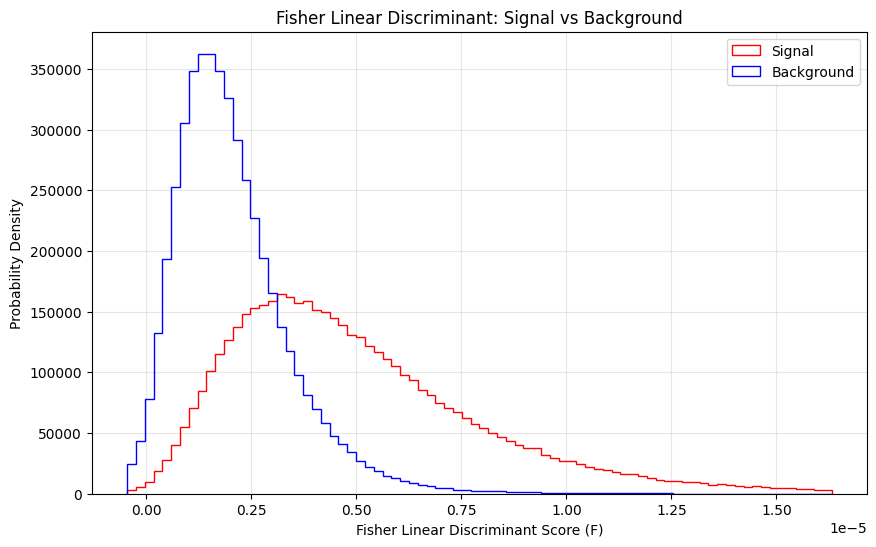

In [137]:
all_scores = np.concatenate([F_sig, F_bkg])

low, high = np.percentile(all_scores, [0.5, 99.5])
bins = np.linspace(low, high, 81)

plt.figure(figsize=(10, 6))

plt.hist(
    F_sig,
    bins=bins,
    density=True,
    histtype="step",
    color="red",
    label="Signal"
)

plt.hist(
    F_bkg,
    bins=bins,
    density=True,
    histtype="step",
    color="blue",
    label="Background"
)

plt.xlabel("Fisher Linear Discriminant Score (F)")
plt.ylabel("Probability Density")
plt.title("Fisher Linear Discriminant: Signal vs Background")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

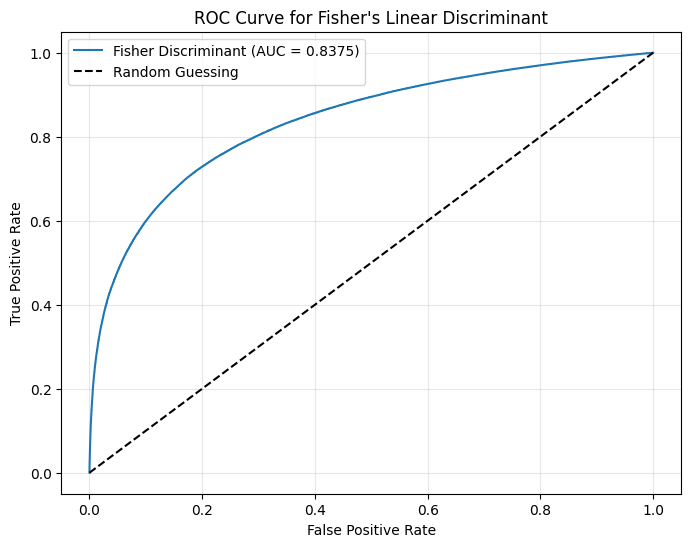

AUC = 0.8375


In [142]:
# 8.3

scores = np.concatenate([F_sig, F_bkg])

labels = np.concatenate([
    np.ones(len(F_sig), dtype=int),
    np.zeros(len(F_bkg), dtype=int)
])

order = np.argsort(-scores, kind="mergesort")
sorted_scores = scores[order]
sorted_labels = labels[order]

ends = np.r_[
    np.where(np.diff(sorted_scores) != 0)[0],
    len(sorted_scores) - 1
]

TP = np.cumsum(sorted_labels)[ends]
FP = (ends + 1) - TP

TPR = np.r_[0, TP / len(F_sig)]
FPR = np.r_[0, FP / len(F_bkg)]

thresholds = np.r_[np.inf, sorted_scores[ends]]

AUC = np.sum(
    np.diff(FPR) * (TPR[1:] + TPR[:-1]) / 2
)

plt.figure(figsize=(8, 6))

plt.plot(
    FPR, TPR,
    label=f"Fisher Discriminant (AUC = {AUC:.4f})"
)

plt.plot(
    [0, 1], [0, 1],
    "k--", label="Random Guessing"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Fisher's Linear Discriminant")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"AUC = {AUC:.4f}")

,Signal,Background,Best Threshold,TPR,FPR,Max Significance
0,10,100,0.000004,0.491631,0.053742,1.532570
1,100,1000,0.000004,0.491631,0.053742,4.846412
2,1000,10000,0.000004,0.491631,0.053742,15.325699
3,10000,100000,0.000004,0.491631,0.053742,48.464117


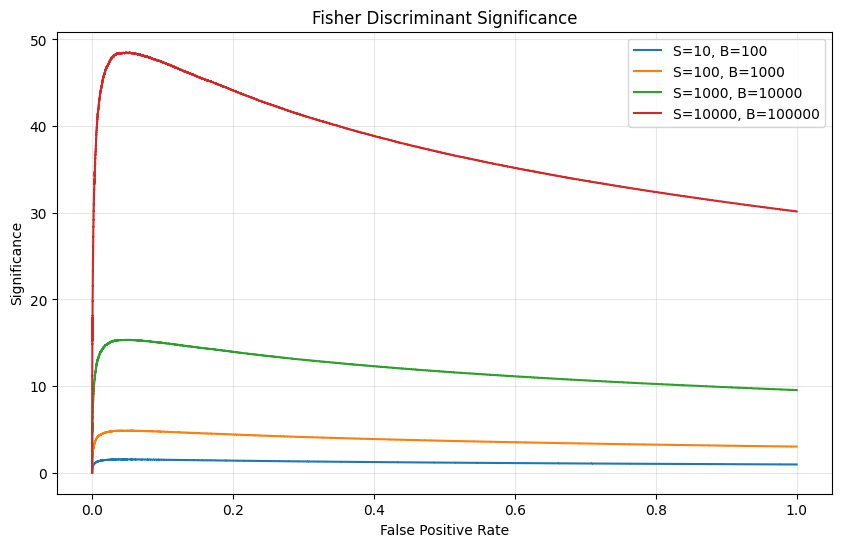

In [144]:
# 8.4

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

results = []

for N_S, N_B in scenarios:

    N_S_prime = TPR * N_S
    N_B_prime = FPR * N_B

    denominator = np.sqrt(N_S_prime + N_B_prime)

    sigma = np.divide(
        N_S_prime,
        denominator,
        out=np.zeros_like(N_S_prime),
        where=denominator > 0
    )

    best_index = np.argmax(sigma)

    results.append({
        "Signal": N_S,
        "Background": N_B,
        "Best Threshold": thresholds[best_index],
        "TPR": TPR[best_index],
        "FPR": FPR[best_index],
        "Max Significance": sigma[best_index]
    })

results_df = pd.DataFrame(results)

display(results_df)
plt.figure(figsize=(10, 6))

for N_S, N_B in scenarios:

    N_S_prime = TPR * N_S
    N_B_prime = FPR * N_B

    denominator = np.sqrt(N_S_prime + N_B_prime)

    sigma = np.divide(
        N_S_prime,
        denominator,
        out=np.zeros_like(N_S_prime),
        where=denominator > 0
    )

    plt.plot(
        FPR,
        sigma,
        label=f"S={N_S}, B={N_B}"
    )

plt.xlabel("False Positive Rate")
plt.ylabel("Significance")
plt.title("Fisher Discriminant Significance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [146]:
# 8.4

# the maximum significance was finding tyhe threshold that produces the highest value of n'_s (square root of (n'_s + n'_b)
# 1.532570, 4.846412, 15.325699, 48.464117